# 07. Mechanistic insights: which molecules do JRGC and GC-GP predict differently?

**Purpose.** Look at the final models molecule by molecule. For every molecule
used in the cross-validation of notebook 04 we put the experimental value, the
JRGC prediction and the GC-GP prediction side by side. From this we find

* the molecules where the two predictions differ the most,
* the molecules that both models predict poorly (likely a limit of the inputs
  or of the experimental data rather than of either model),
* the molecules that JRGC predicts poorly but GC-GP corrects, and the reverse,
* which chemical motifs are common among the poorly predicted molecules.

**What this notebook produces** (in `Output_Data/mechanistic_insights/`)

* `molecule_comparison_all.csv`: one row per unique structure and property with
  both predictions, both errors, ranks and category.
* `duplicate_structures.csv`: every input entry whose structure occurs more
  than once, before merging.
* `<property>_molecule_comparison.csv`: the same table for one property.
* `largest_prediction_differences.csv`: the molecules where the two
  predictions disagree the most.
* `comparison_summary.csv`: errors of both models and category counts per property.
* `motif_enrichment.csv`: share of each chemical motif per category.
* `<property>_error_comparison.png` / `.pdf`: per-molecule error plots (600 dpi).
* `structures/<property>_<category>.png` / `.pdf`: structure grids (600 dpi).
* `results_summary.md`: the results in plain sentences.

**Inputs needed.** The curated datasets from `00_Data_Curation.ipynb` and the
pooled cross-validation predictions from `04_Final_GCGP_CrossValidation.ipynb`
(`Output_Data/final_gcgp_cv/`). With
`jrgcSource = "fitted"` the baseline predictions from `01_JRGC_Baseline.ipynb`
are also needed. Structures are drawn with RDKit.

**Why out-of-fold predictions.** In the cross-validation output each molecule
appears once as a test point and nine times as a training point. Only the test
rows are used here, so every GC-GP value comes from a model that never saw that
molecule.

**One row per structure.** Molecules are identified by structure, not by the
way their SMILES is written. Each SMILES is converted with RDKit to a standard
InChIKey, and entries with the same key are merged into one row (values
averaged, CAS numbers listed) before anything is ranked, counted or drawn. This
catches the same compound written as two different SMILES strings, and isomers
whose SMILES carry no stereochemistry and so cannot be told apart. Section 3.1
lists every merged entry.

## 1. Environment and setup

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder that contains src/gcgp) and make the
# shared code importable. This works whether Jupyter starts in notebooks/ or
# in the repository root.
repoRoot = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gcgp").is_dir())
sys.path.insert(0, str(repoRoot / "src"))

import pandas as pd

from gcgp.settings import checkCuratedData, describeSetup, outputFolder, setGlobalSeed
from gcgp.properties import PROPERTIES, PROPERTY_ORDER
from gcgp.finalConfig import RUN_NAMES
from gcgp.moleculeComparison import (CATEGORY_BOTH, CATEGORY_GCGP_ONLY, CATEGORY_JRGC_ONLY,
                                     CATEGORY_ORDER, compareAllProperties, drawStructureGrid,
                                     duplicateStructures, largestDifferences, motifEnrichment,
                                     plotErrorComparison, summarizeComparison)

setGlobalSeed()
outputDir = outputFolder("mechanistic_insights")
structureDir = outputFolder("mechanistic_insights/structures")
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)
checkCuratedData()
print(describeSetup())

Run mode      : FULL
Input folder  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Input_Data
Output folder : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data
Curated data  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/curated_data
GP workers    : 1 (set GCGP_N_WORKERS to fit restarts in parallel)
Global seed   : 42


## 2. Settings

* `jrgcSource`: which JRGC prediction to compare with.
  * `"raw"` (default): the group-contribution estimate in the input file, as in
    the original analysis. Available for every molecule.
  * `"fitted"`: the fitted linear GC baseline from notebook 01. Only molecules in
    the baseline set are compared, and for its training molecules this is an
    in-sample prediction (the `JRGC_Set` column says which).
* `topN`: a molecule counts as "poorly predicted" by a model when it is among
  that model's `topN` largest absolute errors for the property. The default of
  20 follows the original analysis. Because Pc, Vc, Tc and ΔHvap have only about
  70 molecules, 20 is close to a third of them; a value between 0 and 1 is read
  as a fraction instead (for example `topN = 0.05` for the worst 5% of each
  property), which makes the properties easier to compare.
* `nDifferences`: how many molecules per property to list and label as the
  largest differences between the two predictions.
* `uniqueStructures`: merge entries with the same structure (default True).
* `structureLevel`: `"inchikey"` (default) treats stereoisomers that are written
  with stereochemistry as different structures; `"connectivity"` uses only the
  first block of the InChIKey, so all stereoisomers of a skeleton are merged.
* `nStructures`: how many structures to draw per grid. With `diverseStructures
  = True` a structurally diverse subset is drawn (MaxMin picking on Morgan
  fingerprints, seed 42), so similar molecules do not fill the grid.

The GC-GP predictions are those of the final model of each property (notebook 04):

In [2]:
jrgcSource = "raw"
uniqueStructures = True
structureLevel = "inchikey"
topN = 20
nDifferences = 10
nStructures = 6
diverseStructures = True

pd.DataFrame([{"Property": c, "Run": RUN_NAMES[c]} for c in PROPERTY_ORDER])

,Property,Run
0,Tb,Tb
1,Tm,Tm
2,Pc,Pc
3,Vc,Vc
4,Tc,Tc
5,Hvap,Hvap
6,logP,LogP


## 3. Build the molecule-level comparison

For each property the curated dataset used in notebook 04 is read, and each
out-of-fold prediction is matched to its molecule by row position. The SMILES
of every pair are checked, so a mismatch (for example when the curated data
changed after notebook 04 was run) stops with a clear message instead of
silently pairing the wrong molecules.

Column guide: `Prediction_Difference` is GC-GP minus JRGC; `Error_Reduction`
is the JRGC absolute error minus the GC-GP absolute error, so a positive value
means GC-GP is closer to experiment. Ranks start at 1 for the largest value.

In [3]:
comparisonDf = compareAllProperties(PROPERTY_ORDER, jrgcSource=jrgcSource, topN=topN,
                                    uniqueStructures=uniqueStructures, structureLevel=structureLevel)
assert not comparisonDf.duplicated(["Property", "StructureKey"]).any(), "a structure is listed twice"
comparisonDf.to_csv(outputDir / "molecule_comparison_all.csv", index=False)
for code, group in comparisonDf.groupby("Property"):
    group.sort_values("Difference_Rank").to_csv(outputDir / f"{code}_molecule_comparison.csv", index=False)

comparisonDf.groupby("Property", sort=False).agg(
    Entries=("N_Entries", "sum"), Unique_structures=("StructureKey", "nunique"))

,Entries,Unique_structures
Property,,
Tb,886,883
Tm,1839,1829
Pc,75,75
Vc,69,69
Tc,70,70
Hvap,70,70
logP,2978,2978


### 3.1 Structures that occur more than once

Every entry whose structure appears more than once in the curated data used by
notebook 04, before merging. Two kinds can occur:

* `Experimental_Spread` = 0 and `Same_SMILES_Text` = False: the same compound
  entered twice with differently written SMILES (a true duplicate).
* `Experimental_Spread` > 0: different compounds, usually stereoisomers or
  cis/trans isomers with different CAS numbers, whose SMILES do not encode the
  difference. The GP sees identical inputs for them, so it cannot predict
  different values.

`Different_Folds` = True means a copy of the structure was in the training set
of the fold that predicted this entry. For a true duplicate this makes that
cross-validation prediction optimistic; properties where this matters can be
added to `REMOVE_DUPLICATE_STRUCTURES` in `src/gcgp/curation.py`.

In [4]:
duplicateDf = pd.concat([duplicateStructures(code, structureLevel=structureLevel)
                         for code in comparisonDf["Property"].unique()], ignore_index=True)
duplicateDf.to_csv(outputDir / "duplicate_structures.csv", index=False)

if duplicateDf.empty:
    print("Every structure occurs once.")
else:
    groups = duplicateDf.groupby(["Property", "StructureKey"]).agg(
        Spread=("Experimental_Spread", "first"), DifferentFolds=("Different_Folds", "first"))
    overview = groups.groupby("Property").agg(
        Repeated_structures=("Spread", "size"), True_duplicates=("Spread", lambda s: int((s == 0).sum())),
        Isomer_groups=("Spread", lambda s: int((s > 0).sum())),
        Copies_in_other_folds=("DifferentFolds", "sum"))
    display(overview)
    display(duplicateDf.head(20))

,Repeated_structures,True_duplicates,Isomer_groups,Copies_in_other_folds
Property,,,,
Tb,3,0,3,3
Tm,9,1,8,8


,Property,Run,RowIndex,Fold,CAS Reg. No.,PubChem SMILES,Experimental,JRGC_Raw,GCGP,StructureKey,Canonical_SMILES,N_Entries,Experimental_Spread,Different_Folds,Same_SMILES_Text
0,Tb,Tb,741,8,300-62-9,CC(CC1=CC=CC=C1)N,471.15,504.29,497.021,KWTSXDURSIMDCE-UHFFFAOYSA-N,CC(N)Cc1ccccc1,2.0,5.5,True,True
1,Tb,Tb,742,3,51-64-9,CC(CC1=CC=CC=C1)N,476.65,504.29,498.196,KWTSXDURSIMDCE-UHFFFAOYSA-N,CC(N)Cc1ccccc1,2.0,5.5,True,True
2,Tb,Tb,104,4,1190-76-7,CC=CC#N,379.15,397.36,394.204,NKKMVIVFRUYPLQ-UHFFFAOYSA-N,CC=CC#N,2.0,14.0,True,True
3,Tb,Tb,105,10,627-26-9,CC=CC#N,393.15,397.36,394.882,NKKMVIVFRUYPLQ-UHFFFAOYSA-N,CC=CC#N,2.0,14.0,True,True
4,Tb,Tb,739,5,24840-05-9,C1=CC=C(C=C1)C=CC#N,522.15,538.44,519.520,ZWKNLRXFUTWSOY-UHFFFAOYSA-N,N#CC=Cc1ccccc1,2.0,14.8,True,True
5,Tb,Tb,740,6,1885-38-7,C1=CC=C(C=C1)C=CC#N,536.95,538.44,520.016,ZWKNLRXFUTWSOY-UHFFFAOYSA-N,N#CC=Cc1ccccc1,2.0,14.8,True,True
6,Tm,Tm,169,7,617-45-8,C(C(C(=O)O)N)C(=O)O,550.65,524.30,497.644,CKLJMWTZIZZHCS-UHFFFAOYSA-N,NC(CC(=O)O)C(=O)O,2.0,7.5,True,True
7,Tm,Tm,170,3,56-84-8,C(C(C(=O)O)N)C(=O)O,543.15,524.30,498.475,CKLJMWTZIZZHCS-UHFFFAOYSA-N,NC(CC(=O)O)C(=O)O,2.0,7.5,True,True
8,Tm,Tm,866,8,90-81-3,CC(C(C1=CC=CC=C1)O)NC,349.65,312.36,308.496,KWGRBVOPPLSCSI-UHFFFAOYSA-N,CNC(C)C(O)c1ccccc1,3.0,36.5,True,True
9,Tm,Tm,867,3,321-98-2,CC(C(C1=CC=CC=C1)O)NC,313.15,312.36,310.049,KWGRBVOPPLSCSI-UHFFFAOYSA-N,CNC(C)C(O)c1ccccc1,3.0,36.5,True,True


## 4. Results

### 4.1 Overview per property

Errors are in the units of each property. `Frac_GCGP_Closer` is the share of
molecules for which GC-GP is closer to the experimental value than JRGC. The
last three columns count the molecules in each category.

In [5]:
summaryDf = summarizeComparison(comparisonDf)
summaryDf.to_csv(outputDir / "comparison_summary.csv", index=False)
summaryDf

,Property,Run,N_Entries,N_Molecules,N_Merged_Structures,N_Isomer_Groups,JRGC_MAE,GCGP_MAE,JRGC_RMSE,GCGP_RMSE,Frac_GCGP_Closer,Median_Error_Reduction,Median_Abs_Prediction_Difference,Max_Abs_Prediction_Difference,N_Poorly predicted by both,"N_Poor JRGC, corrected by GC-GP",N_Poor GC-GP only
0,Tb,Tb,886,883,3,3,25.829,20.804,32.886,26.591,0.590,1.608,5.871,74.075,6,14,14
1,Tm,Tm,1839,1829,9,8,77.969,43.609,102.476,55.009,0.660,13.961,31.875,334.691,1,19,19
2,Pc,Pc,75,75,0,0,3.369,3.590,5.427,5.550,0.467,0.000,0.813,10.039,16,4,4
3,Vc,Vc,69,69,0,0,12.978,13.233,20.586,18.116,0.377,-1.265,2.391,38.419,15,5,5
4,Tc,Tc,70,70,0,0,23.407,24.863,30.359,32.183,0.371,-0.481,2.951,107.933,19,1,1
5,Hvap,Hvap,70,70,0,0,1.938,1.585,2.400,1.962,0.514,0.008,0.838,3.618,12,8,8
6,logP,LogP,2978,2978,0,0,0.467,0.422,0.750,0.675,0.543,0.019,0.175,4.744,14,6,6


### 4.2 Molecules where the two predictions differ most

These are the molecules where the GP changes the JRGC estimate the most. The
`Category` column tells whether either model has one of its `topN` largest
errors for that molecule, and `Error_Reduction` whether the change brought the
prediction closer to experiment. The rank numbers are the labels used in the figures below.

In [6]:
differencesDf = largestDifferences(comparisonDf, nDifferences)
differencesDf.to_csv(outputDir / "largest_prediction_differences.csv", index=False)
differencesDf

,Property,Difference_Rank,CAS Reg. No.,Canonical_SMILES,N_Entries,Experimental,JRGC,GCGP,GCGP_95CI,Prediction_Difference,JRGC_AbsError,GCGP_AbsError,Error_Reduction,Category
0,Tb,1,86-00-0,O=[N+]([O-])c1ccccc1-c1ccccc1,1,593.15,684.340,610.265,52.774,-74.075,91.190,17.115,74.075,"Poor JRGC, corrected by GC-GP"
1,Tb,2,528-29-0,O=[N+]([O-])c1ccccc1[N+](=O)[O-],1,592.15,672.220,599.698,54.615,-72.522,80.070,7.548,72.522,"Poor JRGC, corrected by GC-GP"
2,Tb,3,1761-71-3,NC1CCC(CC2CCC(N)CC2)CC1,1,593.15,671.860,599.563,54.521,-72.297,78.710,6.413,72.297,"Poor JRGC, corrected by GC-GP"
3,Tb,4,645-09-0,NC(=O)c1cccc([N+](=O)[O-])c1,1,585.65,669.660,597.769,53.419,-71.891,84.010,12.119,71.891,"Poor JRGC, corrected by GC-GP"
4,Tb,5,2272-45-9,Cc1ccc(N=Cc2ccccc2)cc1,1,591.15,654.940,587.328,52.582,-67.612,63.790,3.822,59.968,Not among the worst for either
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,logP,6,,O=[N+]([O-])N(CC([N+](=O)[O-])([N+](=O)[O-])[N+](=O)[O-]...,1,0.20,-2.552,-5.832,2.282,-3.279,2.752,6.032,-3.279,Poor GC-GP only
66,logP,7,,CC(N)CC(=O)O,1,-3.10,-0.192,-2.872,0.711,-2.680,2.908,0.228,2.680,Not among the worst for either
67,logP,8,,C[C@@H](O)[C@H](N)C(=O)O,1,-2.90,-1.221,-3.873,0.746,-2.652,1.679,0.973,0.706,Not among the worst for either
68,logP,9,,N[C@@H](CCO)C(=O)O,1,-4.40,-1.219,-3.872,0.746,-2.652,3.181,0.528,2.652,Not among the worst for either


### 4.3 Per-molecule error plots

Left: JRGC absolute error against GC-GP absolute error, one point per
molecule. Points below the dashed line are molecules where GC-GP is closer to
experiment; colours show the category. Right: the two predictions against each
other; points far from the dashed line are where the models disagree. The
numbers are the difference ranks from the table above.

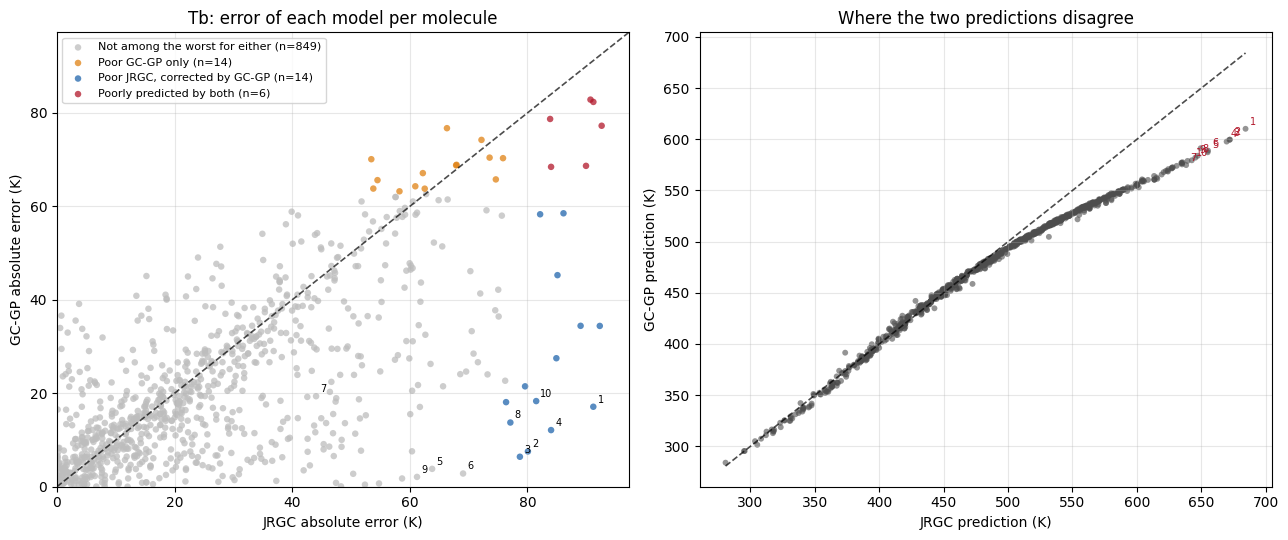

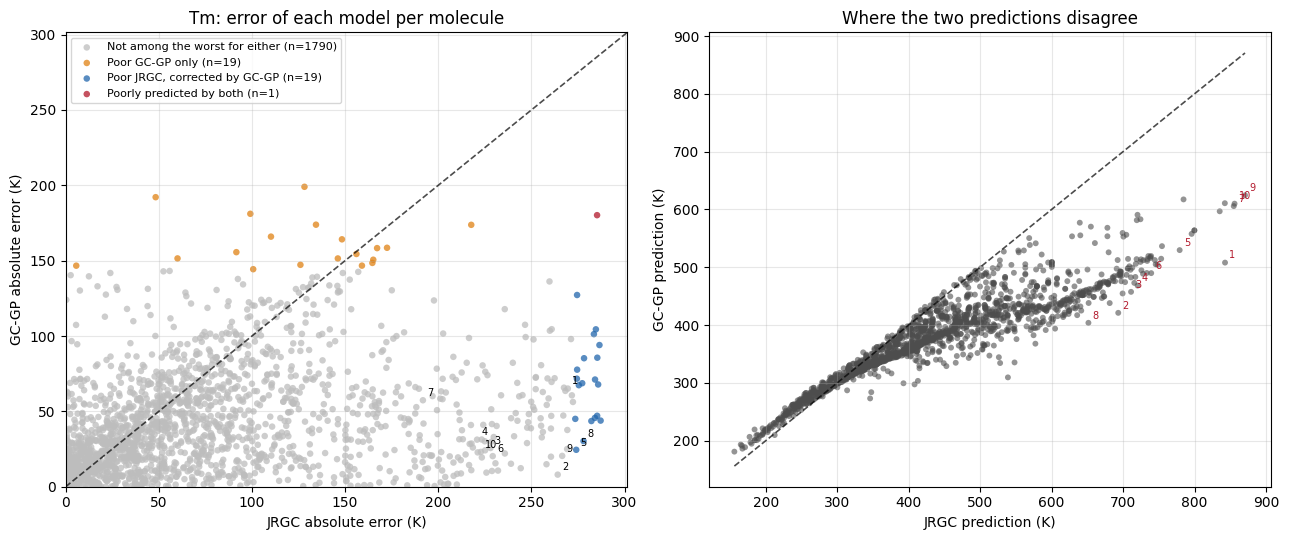

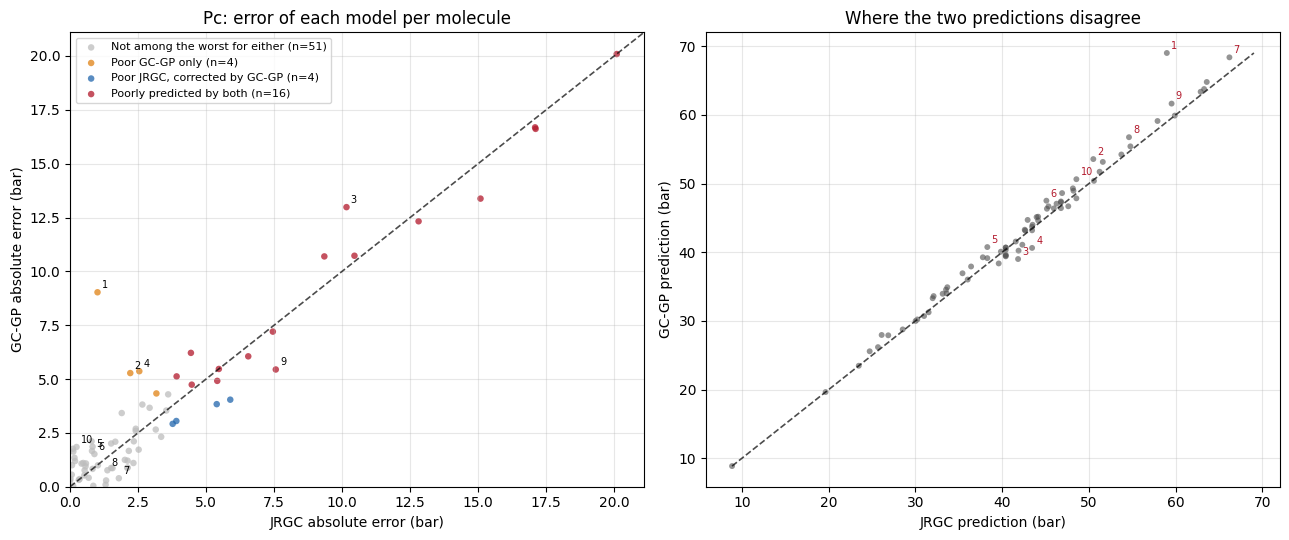

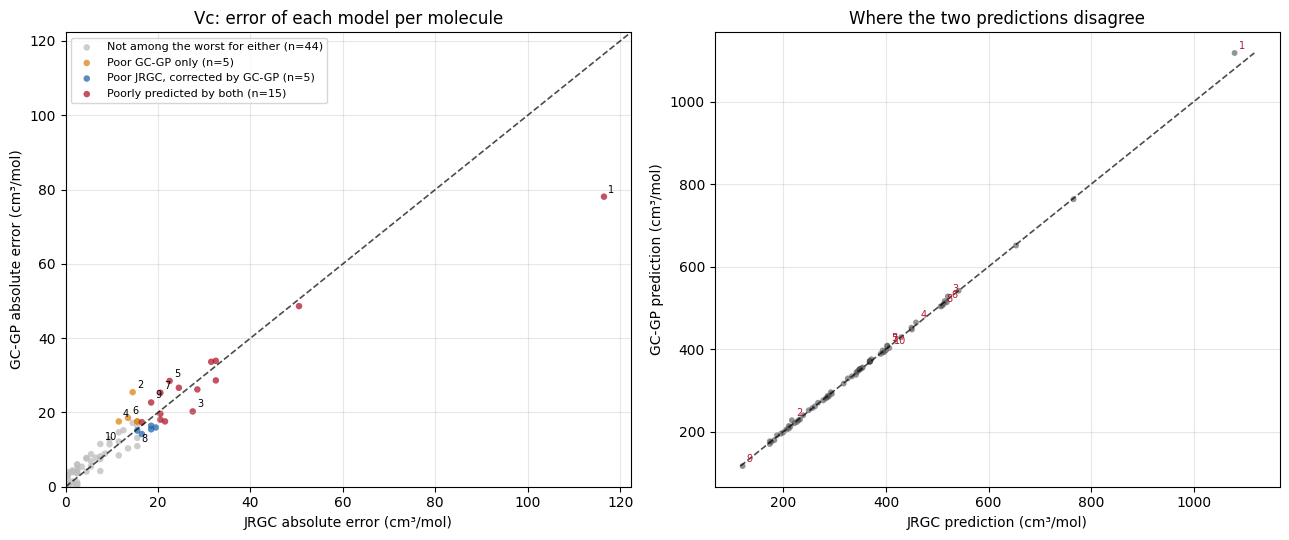

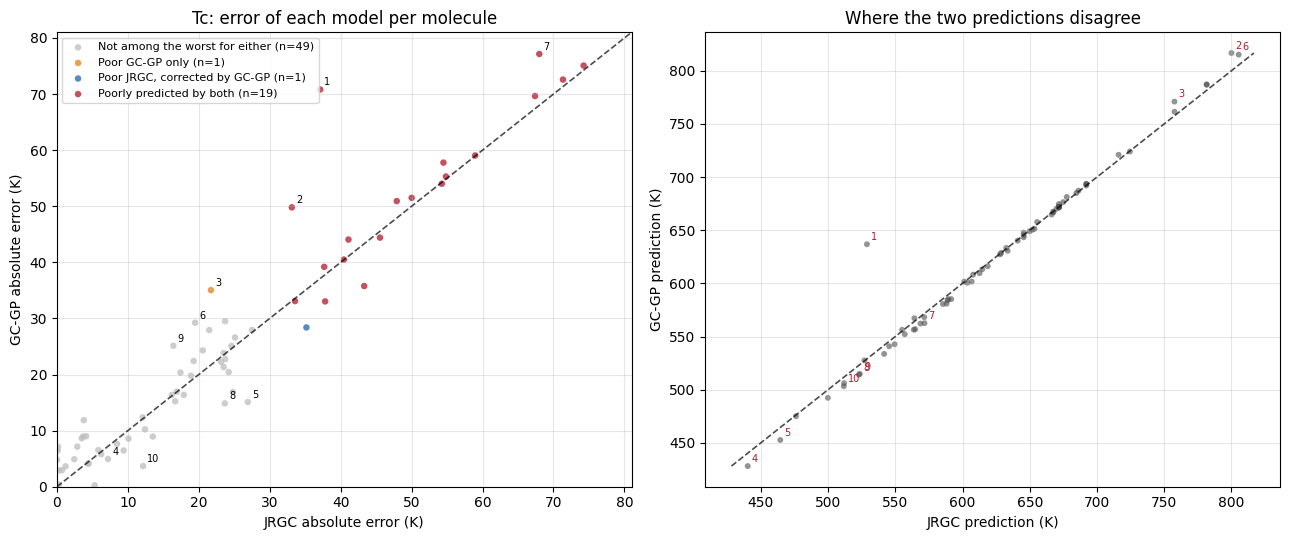

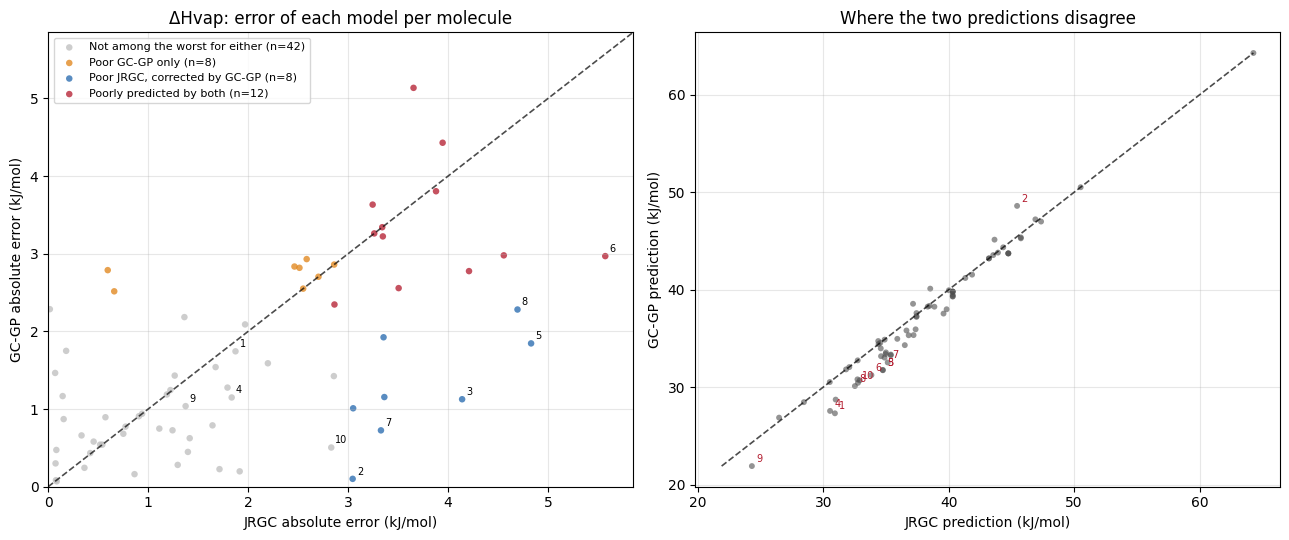

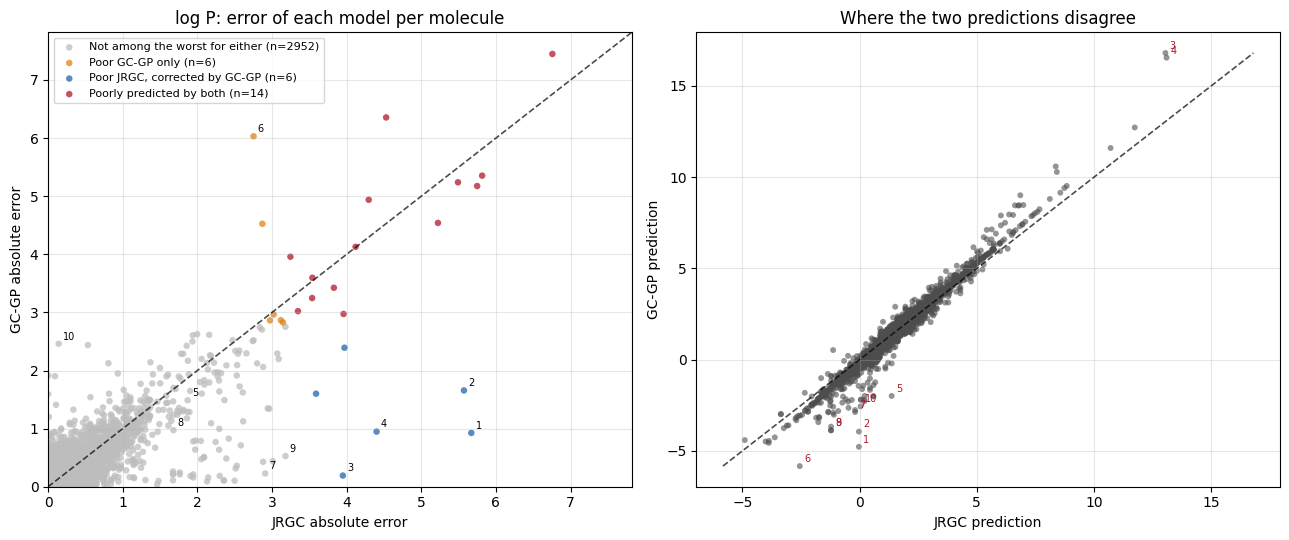

In [7]:
for code in summaryDf["Property"]:
    plotErrorComparison(comparisonDf[comparisonDf["Property"] == code], code,
                        savePath=outputDir / f"{code}_error_comparison.png", nLabels=nDifferences)

### 4.4 Molecules in each category

Molecules that are poorly predicted by both models, sorted by GC-GP error.
The full lists for all categories are in the per-property CSV files. Because
both models contribute exactly `topN` poorly predicted molecules, the
"corrected by GC-GP" and "GC-GP only" counts are always equal; what differs
between properties is how large the overlap ("both") is.

In [8]:
columns = ["Property", "Canonical_SMILES", "N_Entries", "Experimental", "JRGC", "GCGP", "GCGP_95CI",
           "JRGC_Error_Rank", "GCGP_Error_Rank", "GCGP_Inside_95CI"]
bothPoor = comparisonDf[comparisonDf["Category"] == CATEGORY_BOTH].sort_values(["Property", "GCGP_Error_Rank"])
bothPoor[columns].reset_index(drop=True)

,Property,Canonical_SMILES,N_Entries,Experimental,JRGC,GCGP,GCGP_95CI,JRGC_Error_Rank,GCGP_Error_Rank,GCGP_Inside_95CI
0,Hvap,CCCCC(CC)CN,1,40.00,43.655,45.137,3.286,9,1,False
1,Hvap,c1ccc2ncccc2c1,1,49.70,45.754,45.270,3.408,7,2,False
2,Hvap,NC1CCCCC1,1,36.14,40.020,39.945,4.400,8,3,True
3,Hvap,c1ccc2cnccc2c1,1,49.00,45.754,45.367,3.549,17,4,False
4,Hvap,Cc1cc(C)nc(C)c1,1,39.87,43.212,43.212,4.407,14,5,True
...,...,...,...,...,...,...,...,...,...,...
78,logP,NCCCCCCCCCCC(=O)O,1,-1.00,2.541,2.596,1.534,17,12,False
79,logP,O=C(O)CN(CCN(CC(=O)O)CC(=O)O)CC(=O)O,1,-5.90,-2.071,-2.476,1.528,15,13,False
80,logP,NCCCC(N)C(=O)O,1,-4.40,-0.863,-1.153,1.534,18,14,False
81,logP,NCCC(N)C(=O)O,1,-4.60,-1.253,-1.579,1.528,19,15,False


### 4.5 Structures

For every property one grid is drawn per category: molecules poorly predicted
by both models, molecules corrected by GC-GP, and molecules poorly predicted by
GC-GP only. Each legend gives the CAS number, the experimental value, the JRGC
prediction and the GC-GP prediction with its 95% half-width. All grids are
saved; only the "poorly predicted by both" grids are shown here. Each grid
contains distinct structures, drawn from the canonical SMILES; "+n entries"
after a CAS number means that structure was merged from several entries.

Tb: Poorly predicted by both


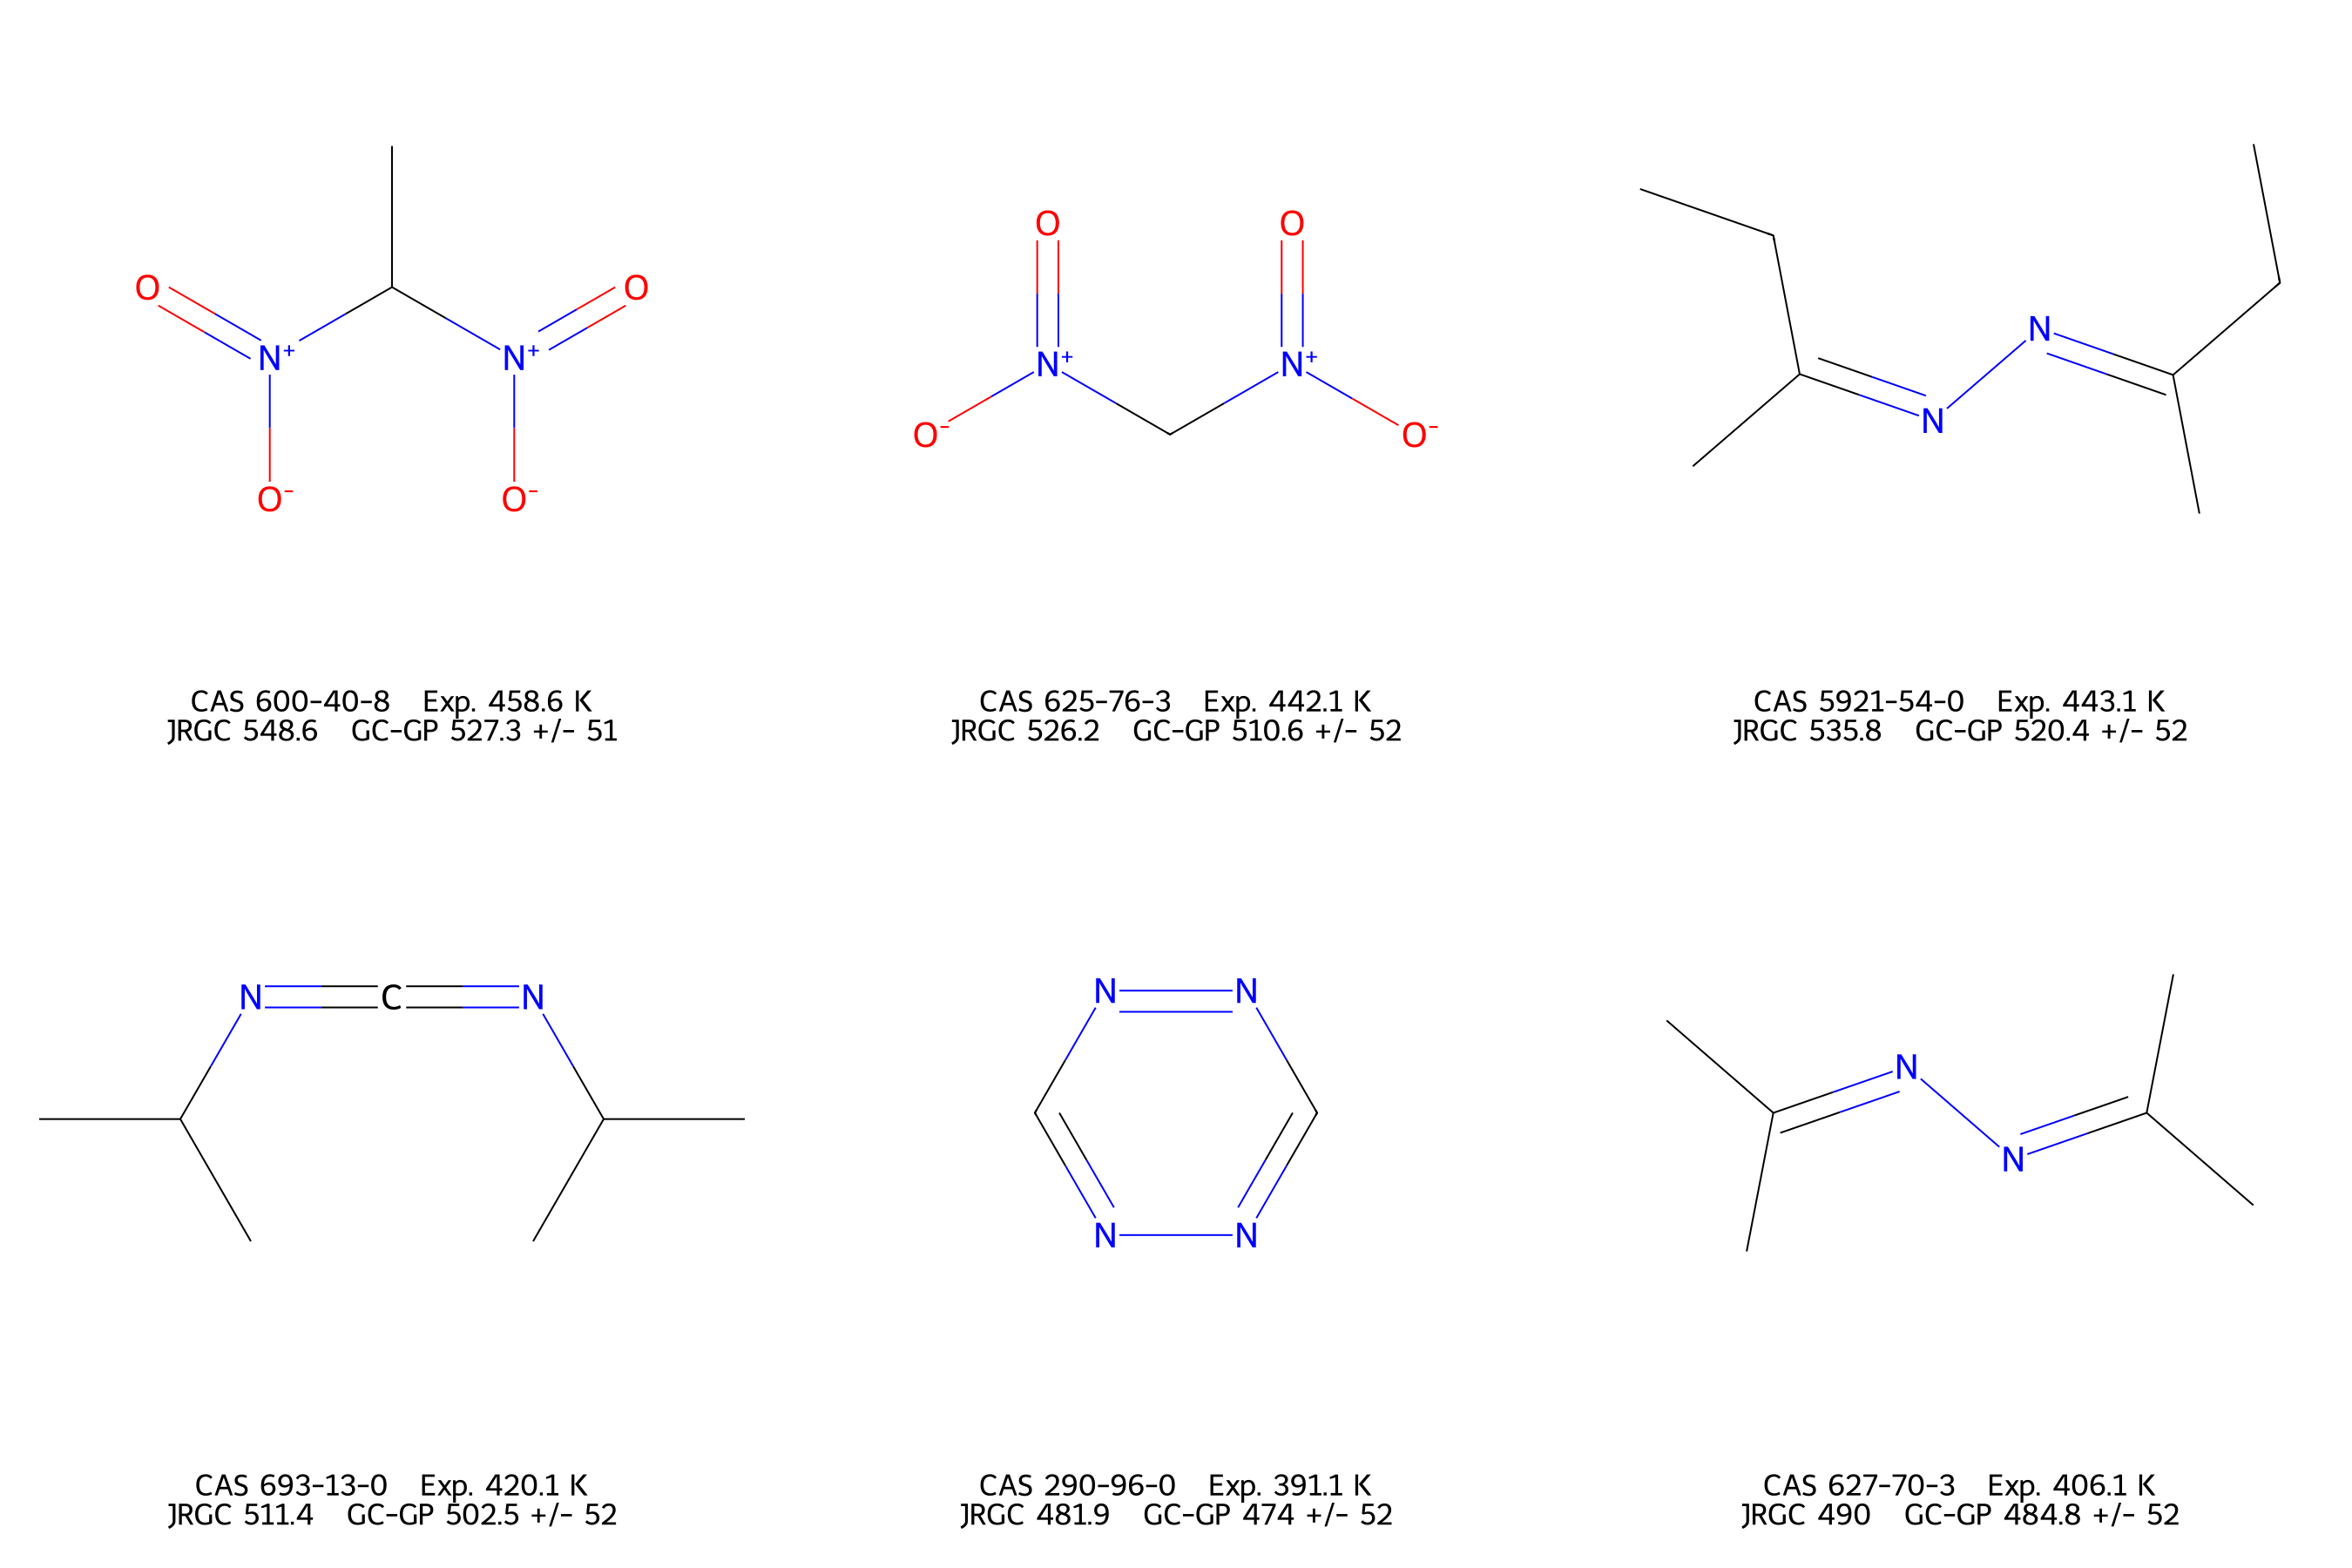

Tm: Poorly predicted by both


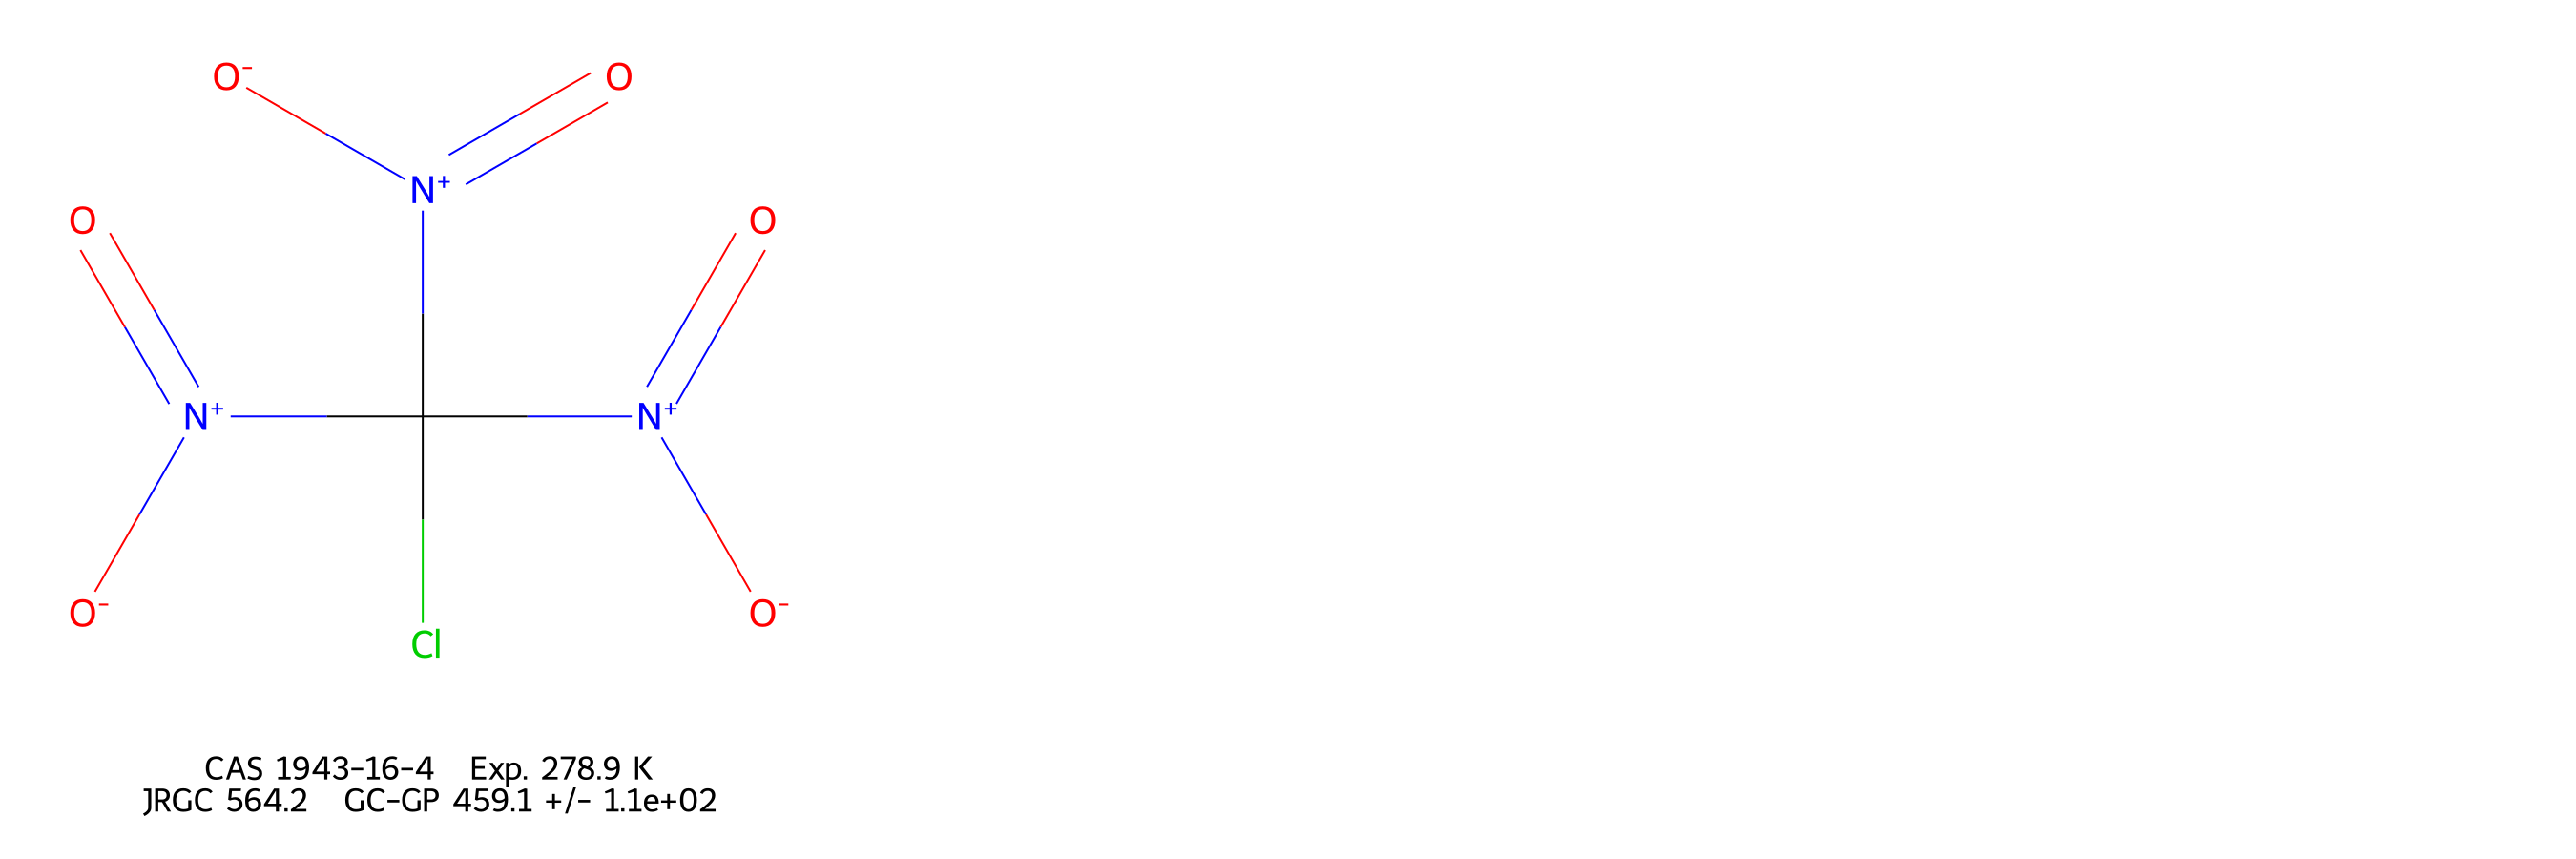

Pc: Poorly predicted by both


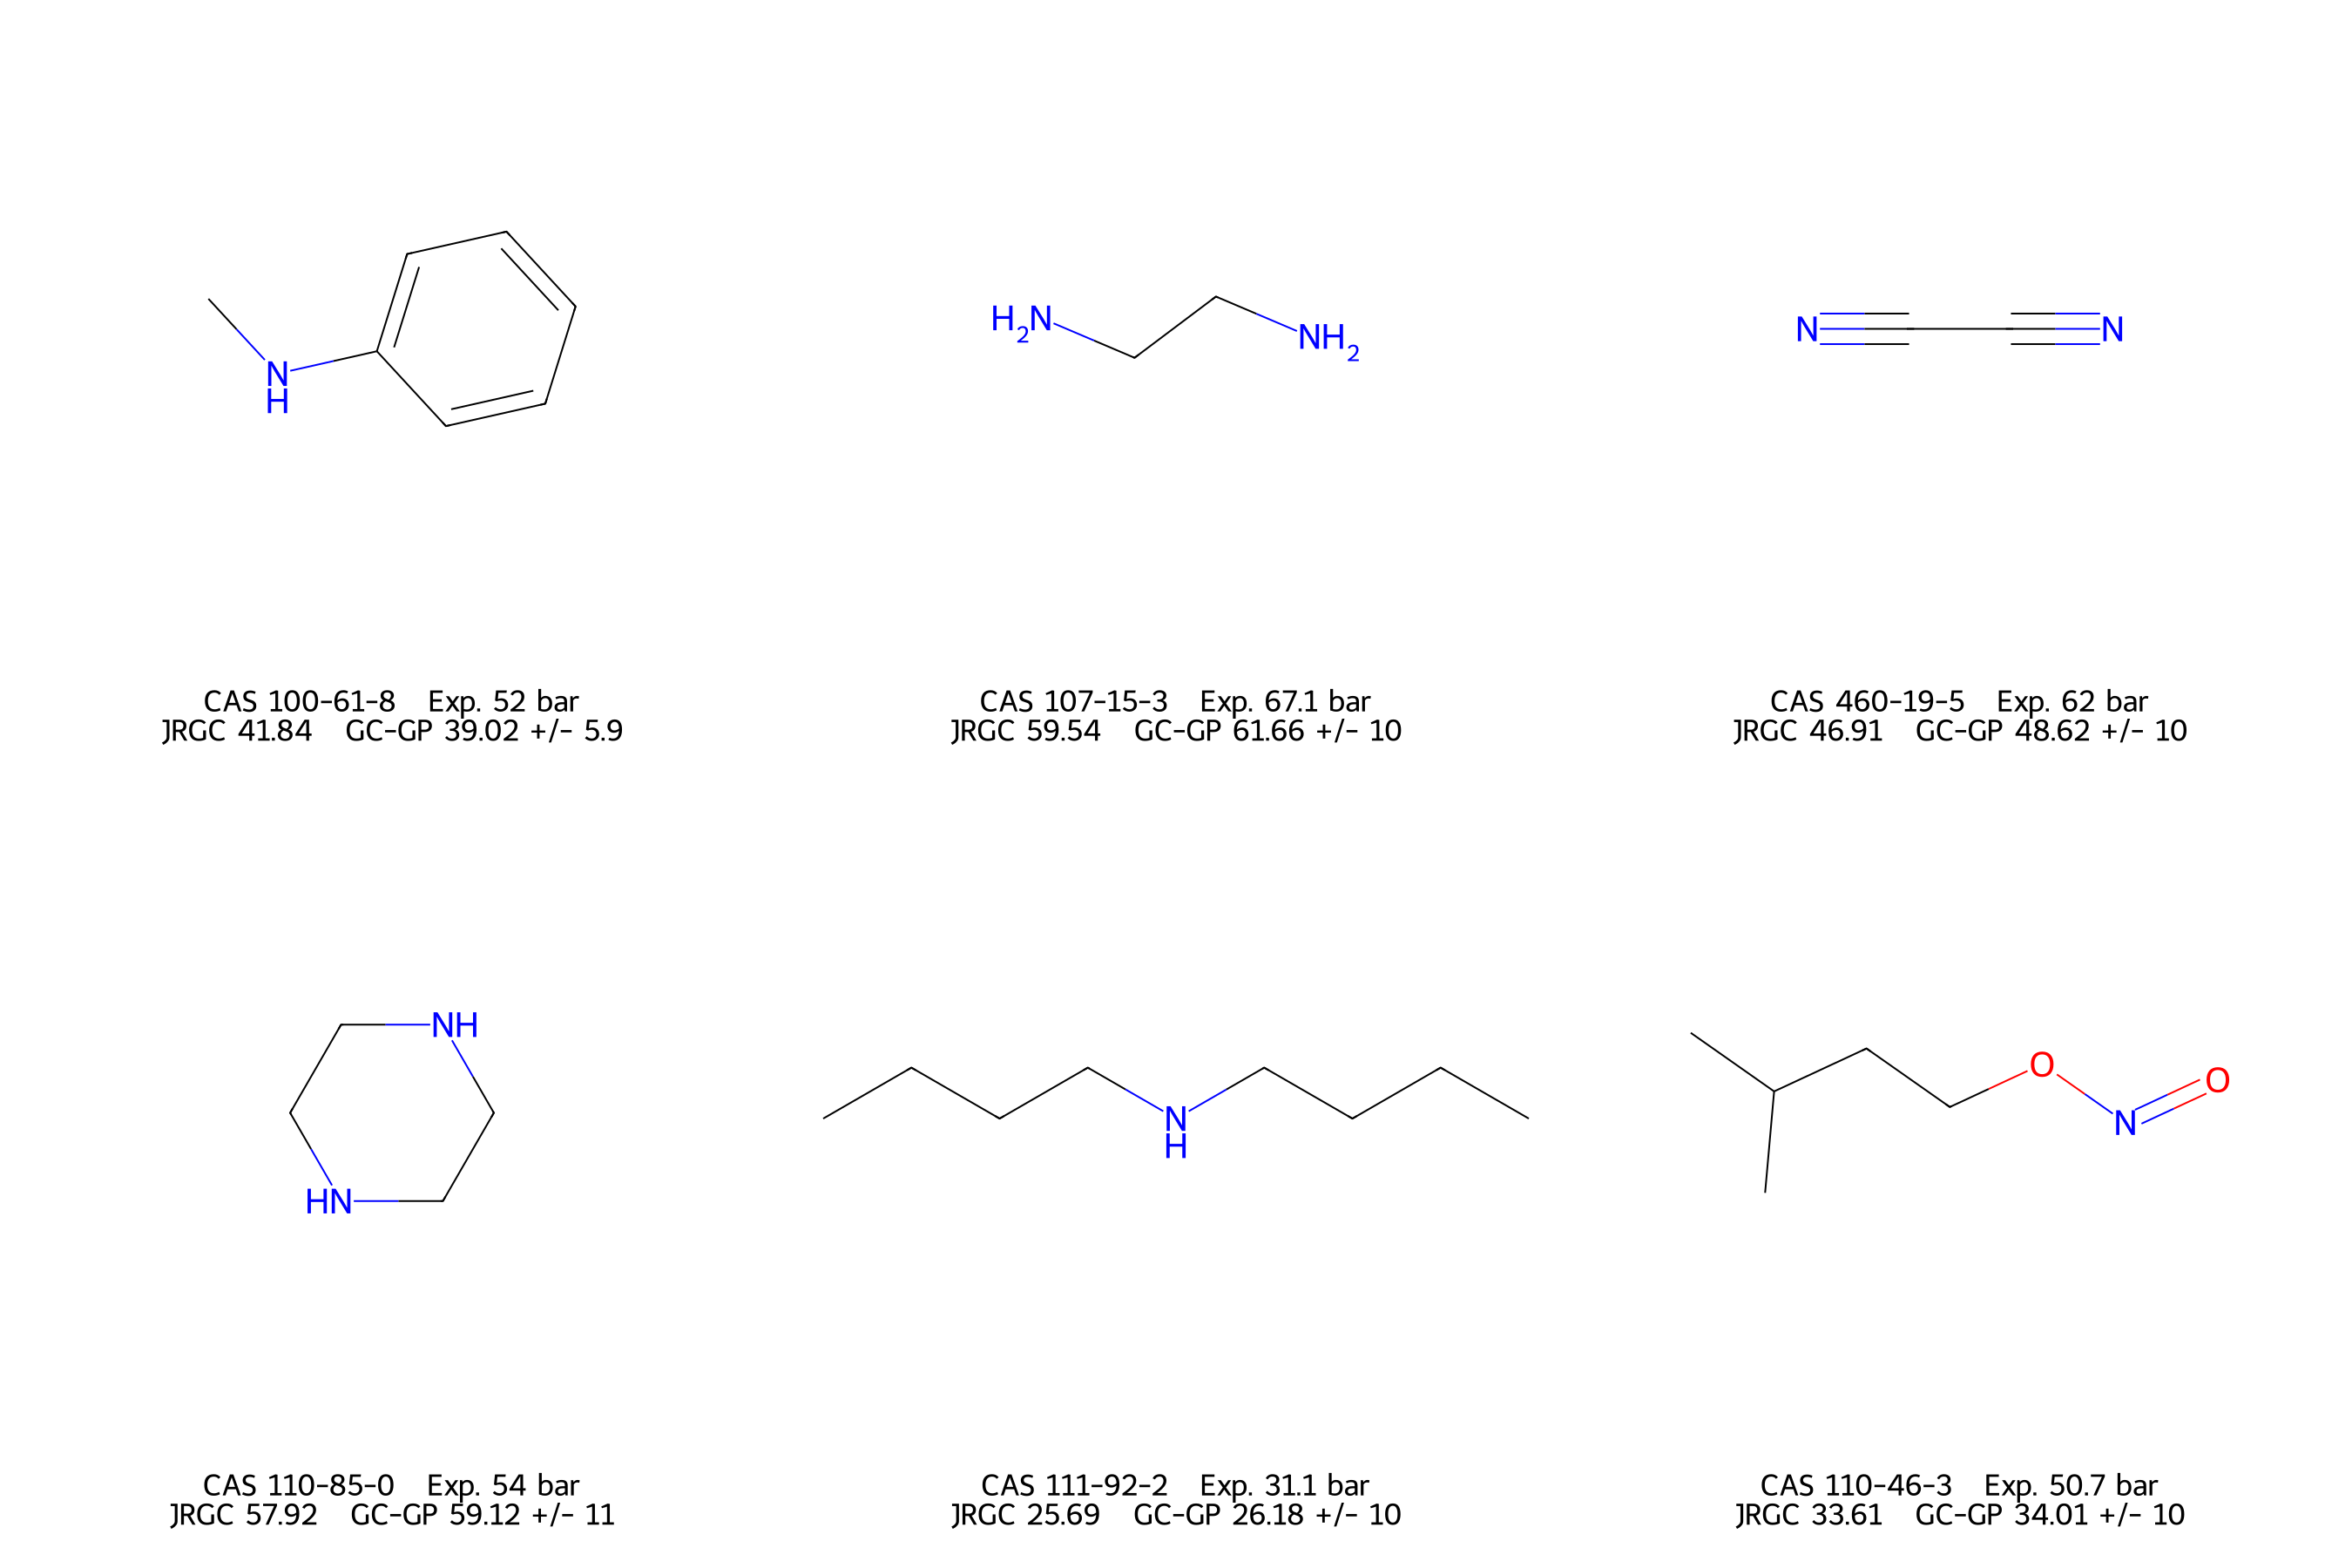

Vc: Poorly predicted by both


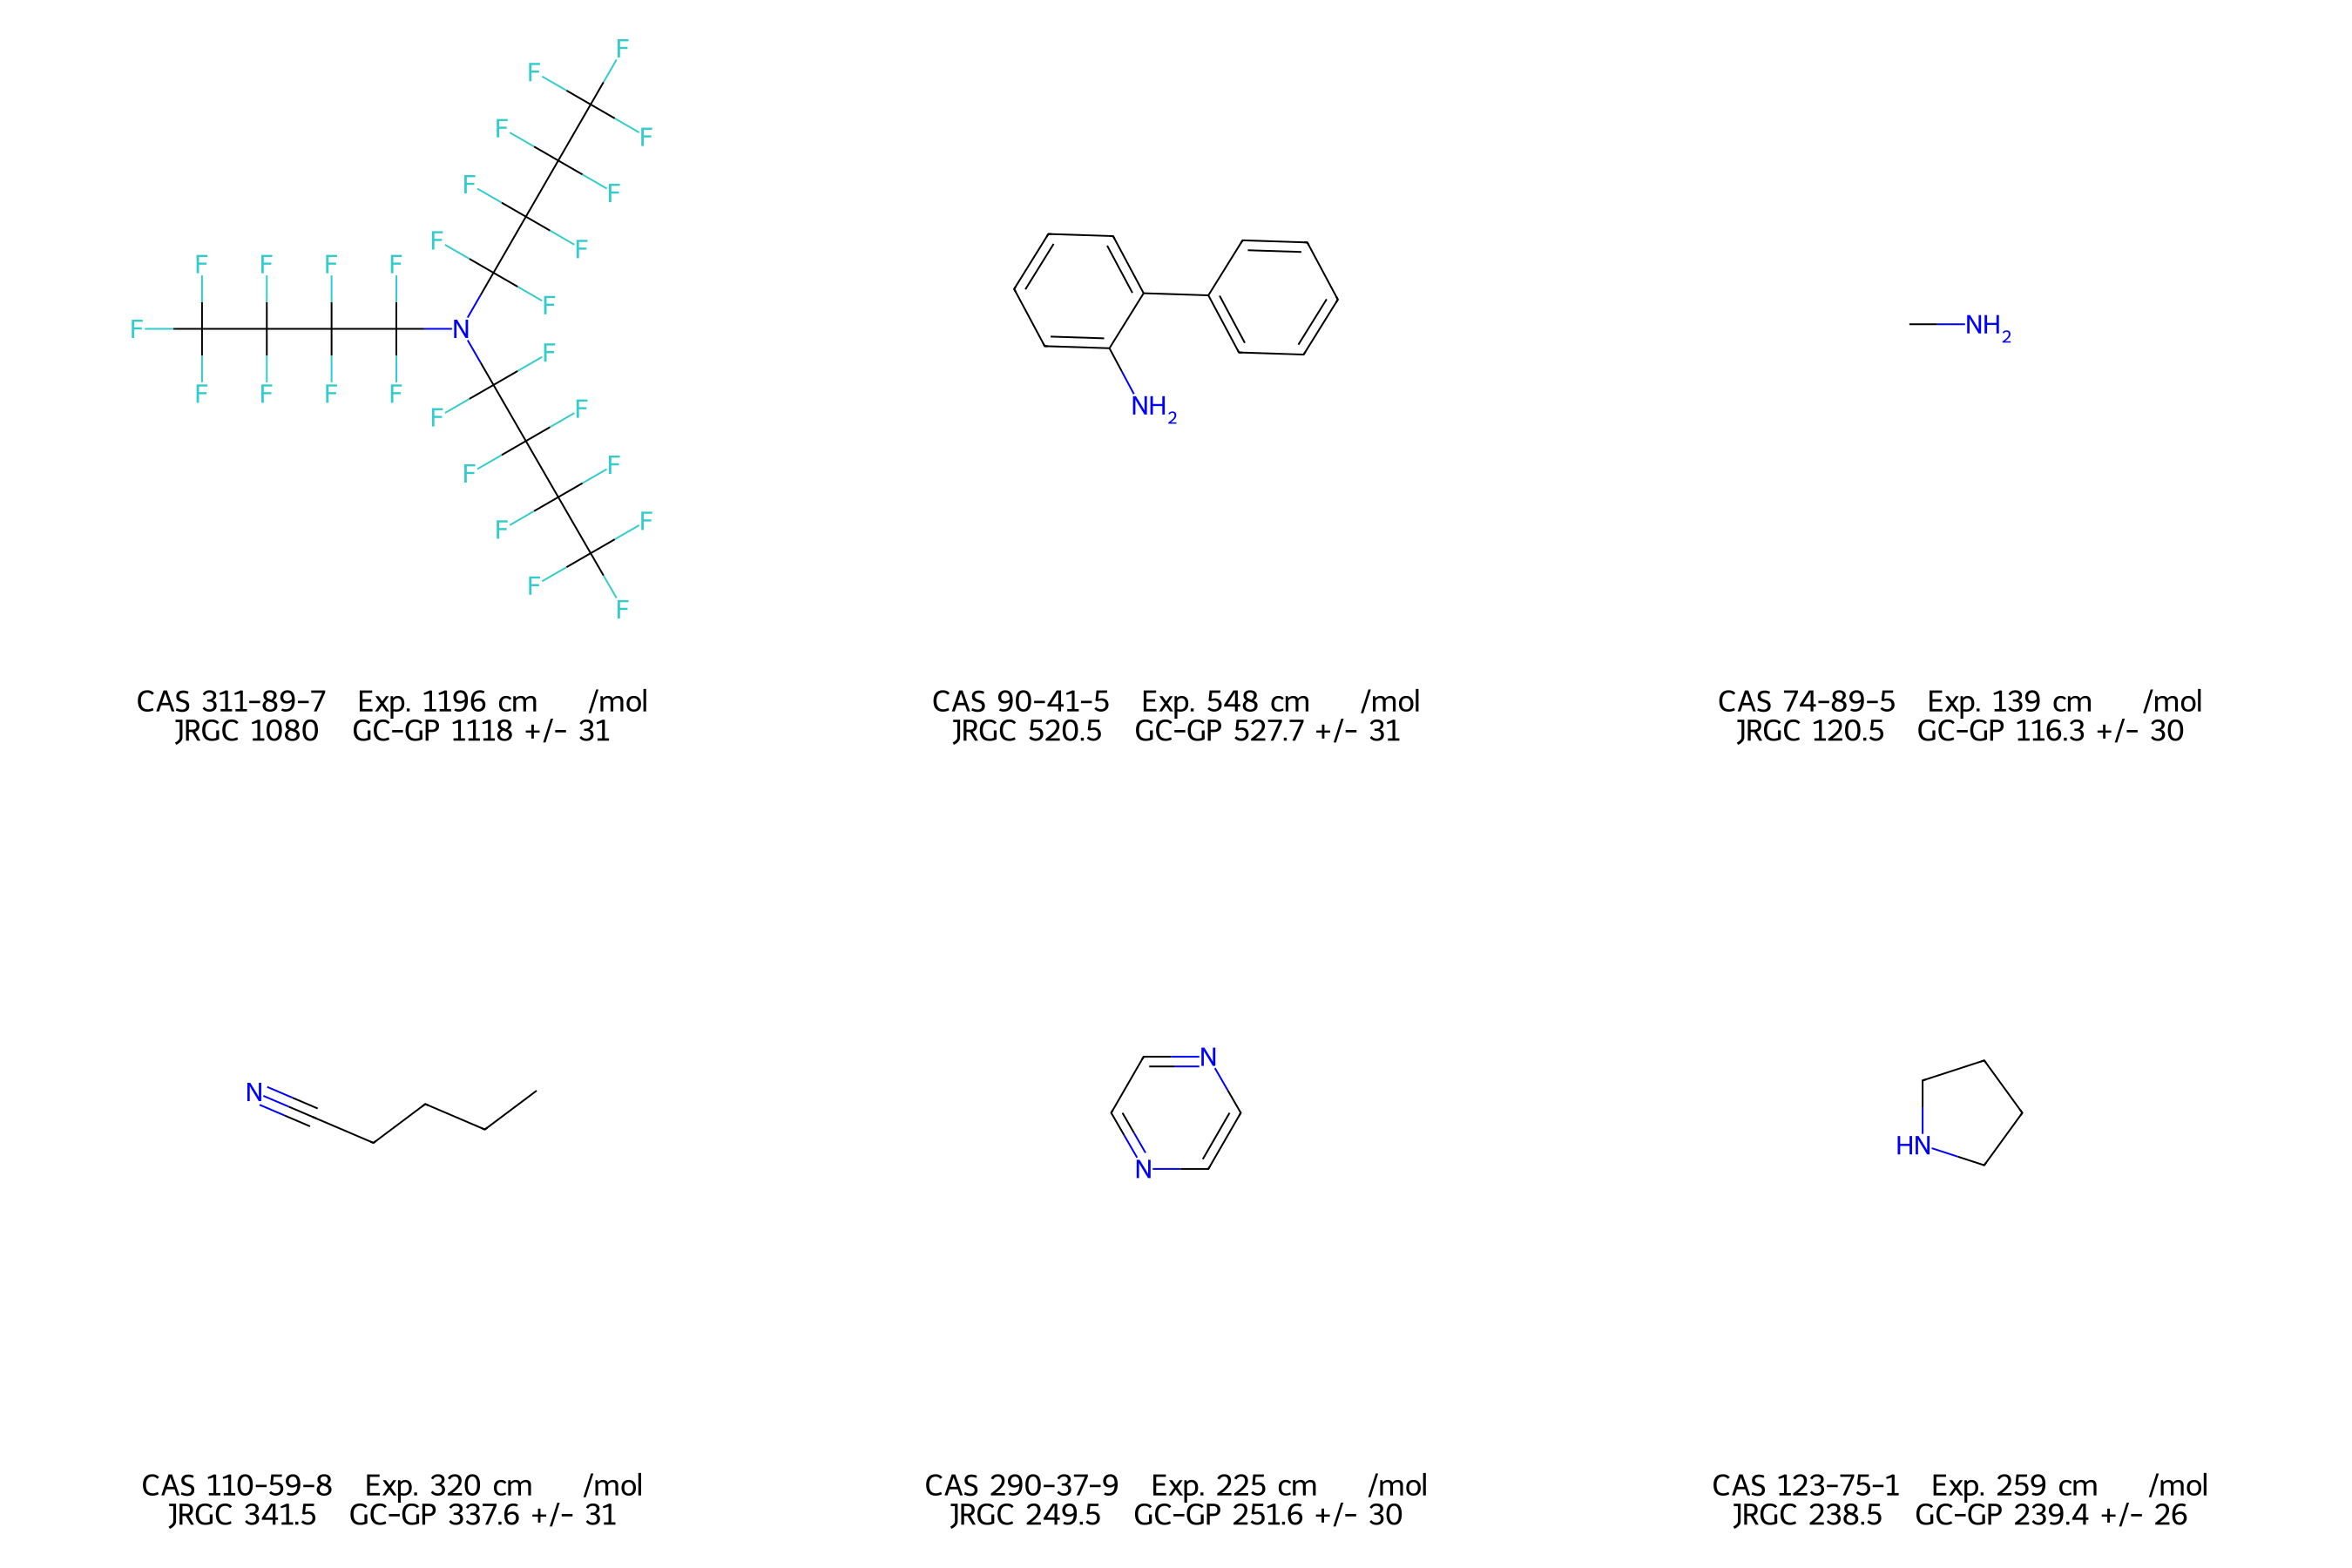

Tc: Poorly predicted by both


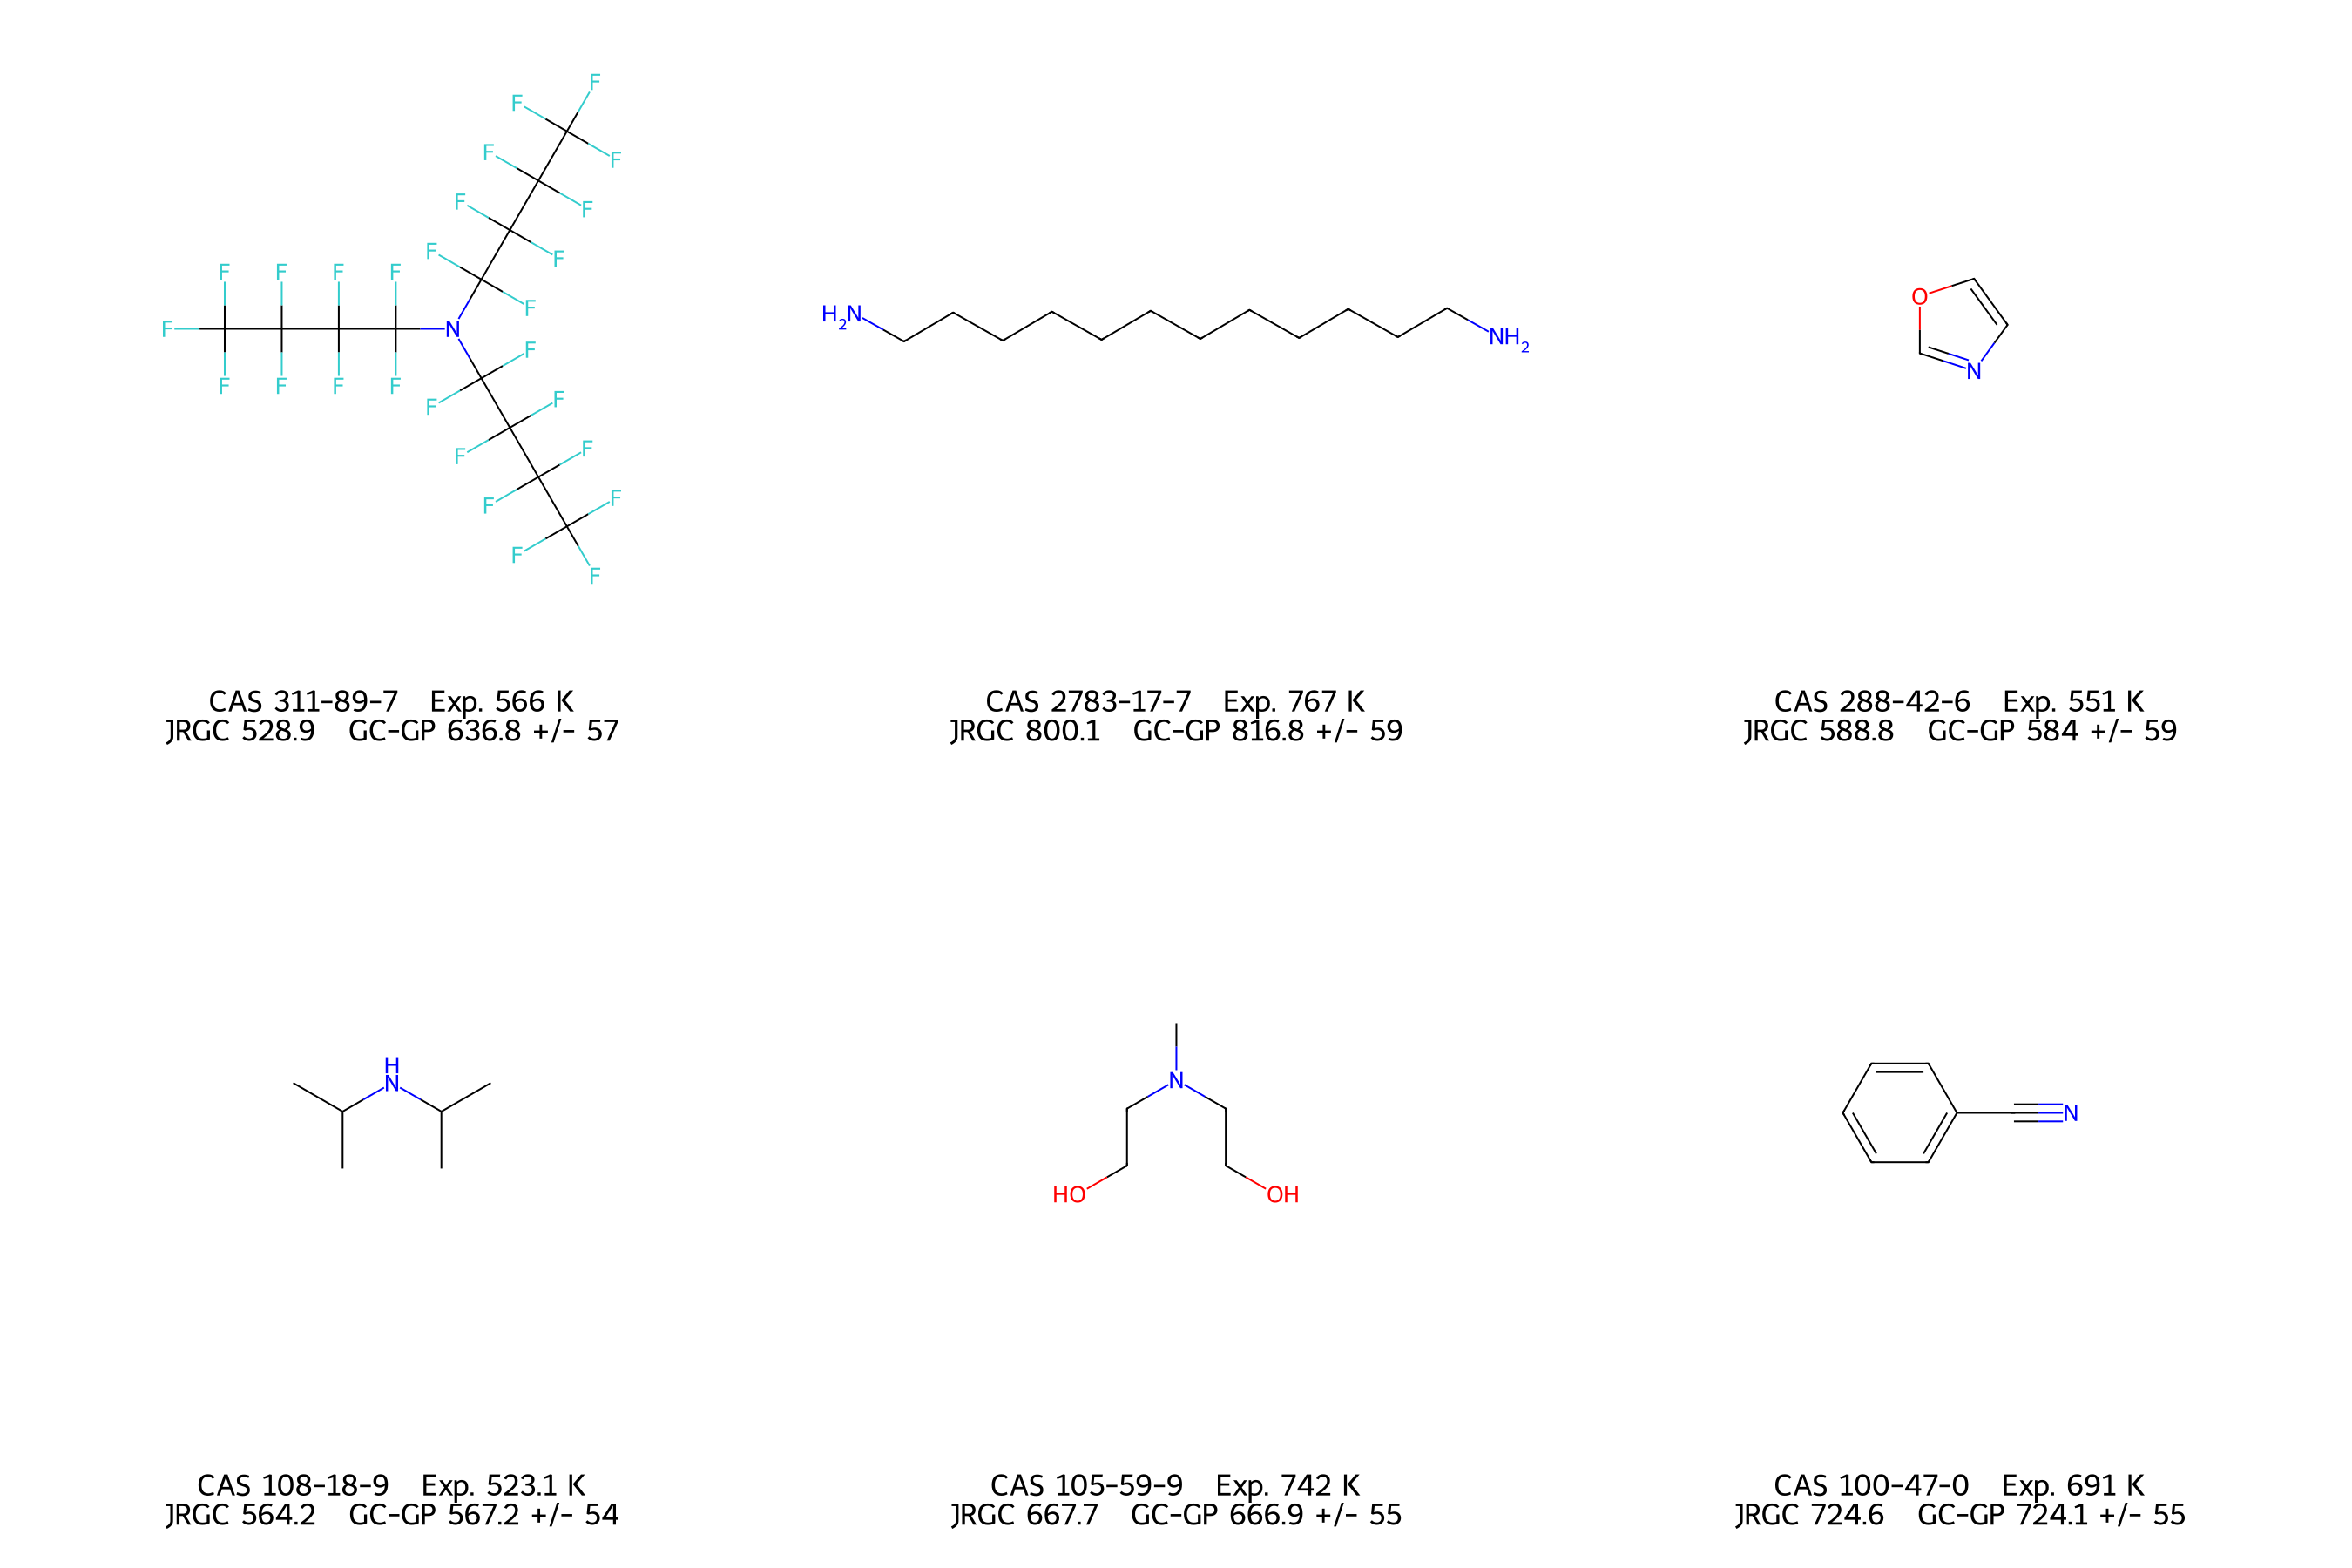

ΔHvap: Poorly predicted by both


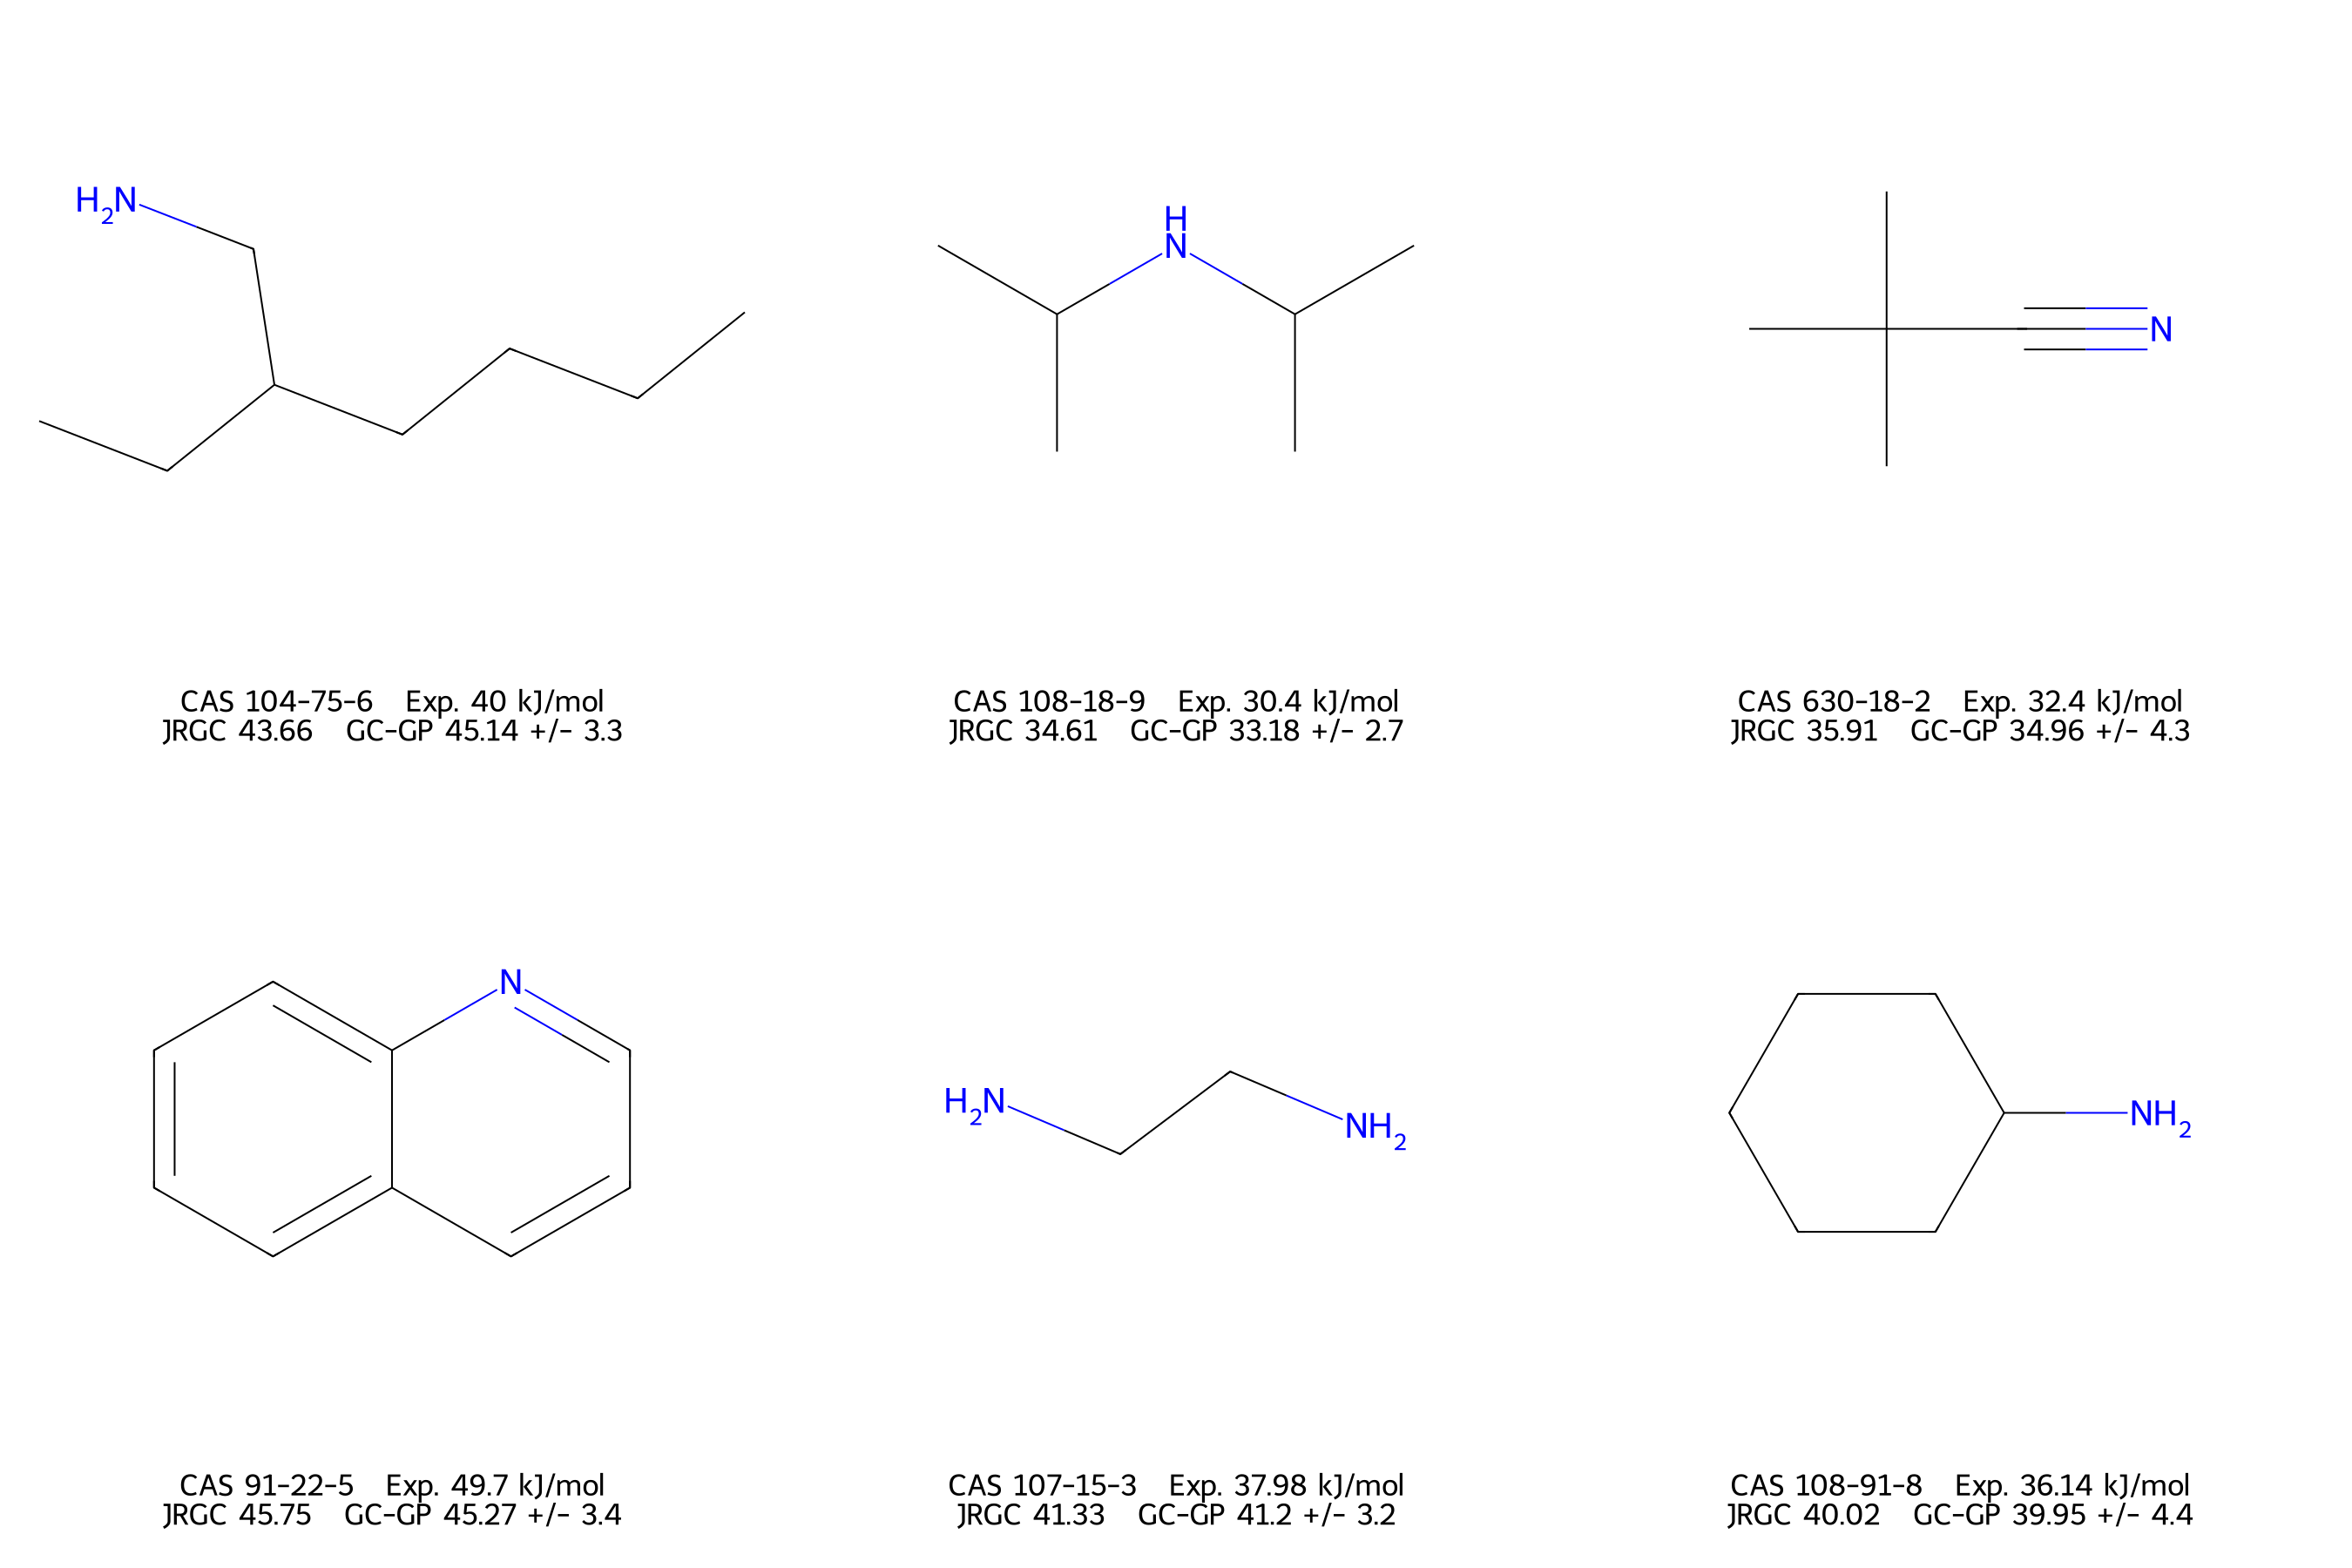

log P: Poorly predicted by both


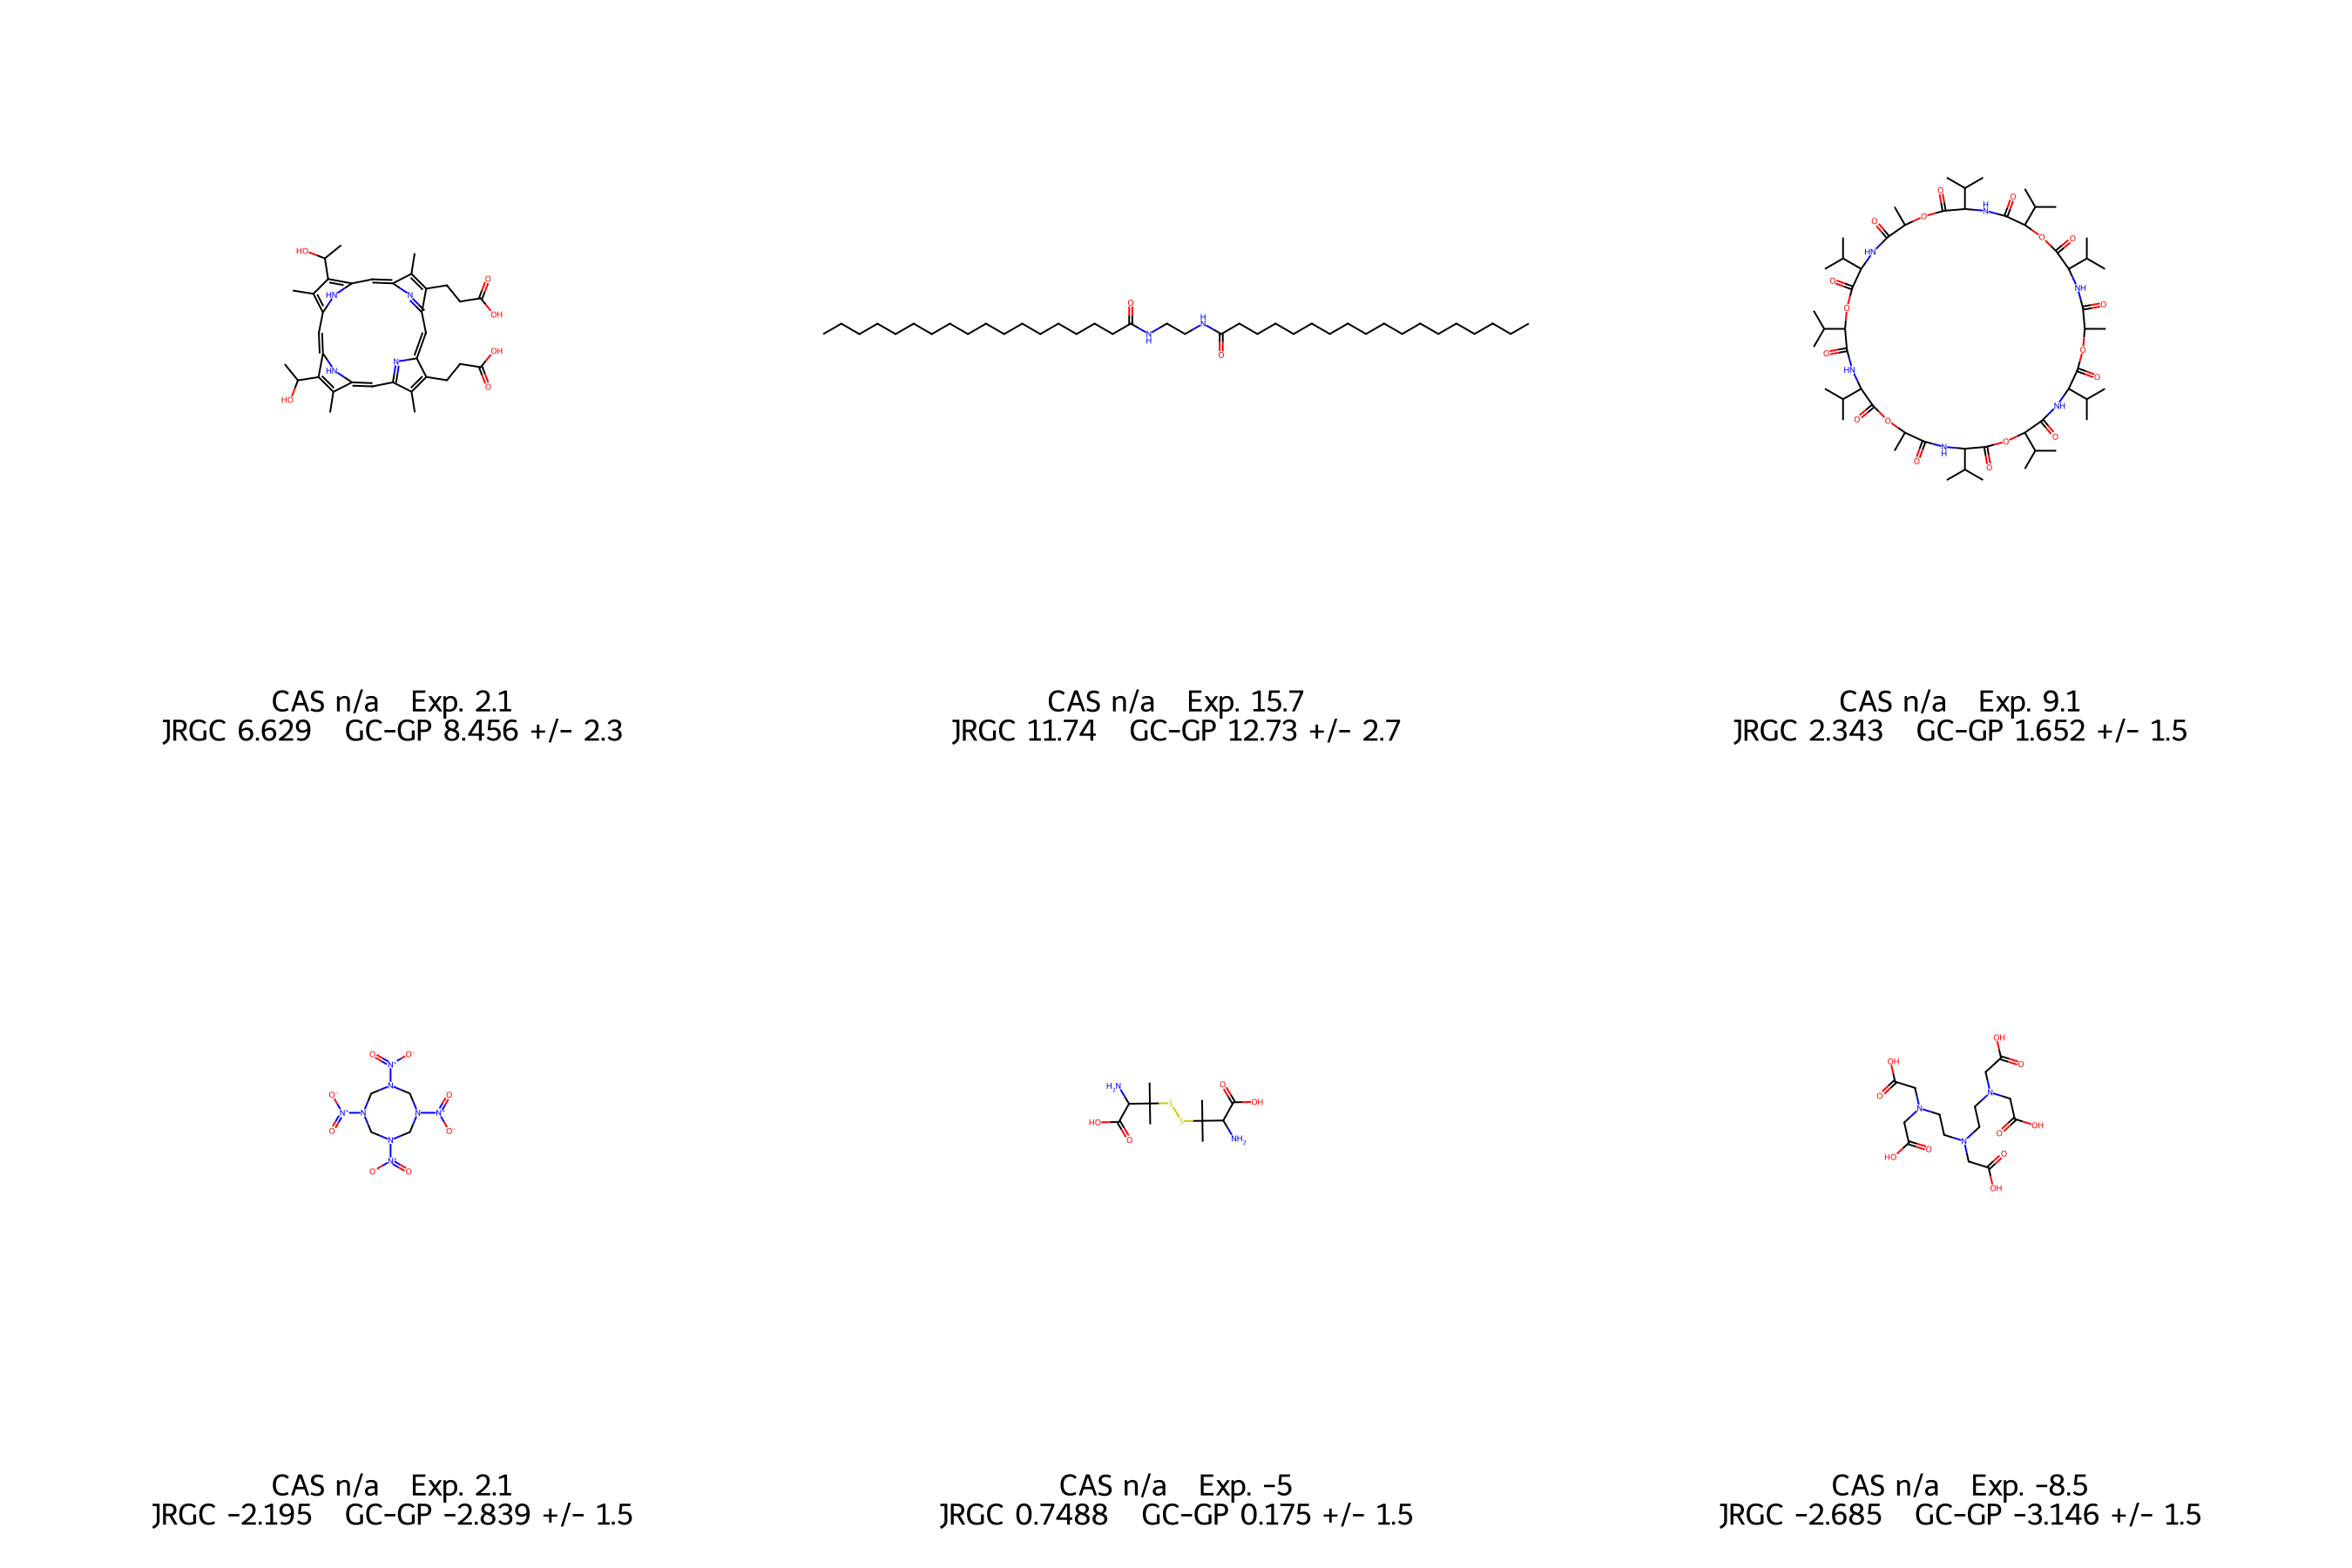

In [9]:
gridCategories = {CATEGORY_BOTH: "poor_both", CATEGORY_JRGC_ONLY: "corrected_by_gcgp",
                  CATEGORY_GCGP_ONLY: "poor_gcgp_only"}
drawnRows = []
for code in summaryDf["Property"]:
    group = comparisonDf[comparisonDf["Property"] == code]
    for category, fileTag in gridCategories.items():
        subset = group[group["Category"] == category].sort_values("Abs_Prediction_Difference", ascending=False)
        if subset.empty:
            continue
        show = category == CATEGORY_BOTH
        if show:
            print(f"{PROPERTIES[code]['label']}: {category}")
        drawn = drawStructureGrid(subset, code, structureDir / f"{code}_{fileTag}.png",
                                  nStructures=nStructures, diverse=diverseStructures, show=show)
        drawnRows.append(drawn.assign(Grid=fileTag))

pd.concat(drawnRows, ignore_index=True).to_csv(structureDir / "drawn_structures.csv", index=False)

### 4.6 Chemical motifs among the poorly predicted molecules

Percentage of molecules that contain each motif, for all molecules of a
property and for each category. The first row of every property gives the
number of molecules in each column. A motif that is much more frequent in a
category than in "All molecules" points to a chemical feature that the model
does not capture. With about 20 molecules per category, differences of a few
percentage points are not meaningful. The motifs are defined as SMARTS patterns
in `gcgp.moleculeComparison.CHEMICAL_MOTIFS`.

In [10]:
enrichmentDf = motifEnrichment(comparisonDf)
enrichmentDf.to_csv(outputDir / "motif_enrichment.csv", index=False)
enrichmentDf.round(1)

,Property,Motif,All molecules,Poorly predicted by both,"Poor JRGC, corrected by GC-GP",Poor GC-GP only
0,Tb,Number of molecules,883.0,6.0,14.0,14.0
1,Tb,Primary amine,12.9,0.0,7.1,0.0
2,Tb,Secondary amine,10.5,0.0,0.0,0.0
3,Tb,Tertiary amine,6.3,0.0,7.1,0.0
4,Tb,Aniline-type N,25.8,0.0,64.3,7.1
...,...,...,...,...,...,...
100,logP,Hydroxyl,18.8,71.4,66.7,66.7
101,logP,Carboxylic acid,8.0,71.4,66.7,66.7
102,logP,Fluorinated,10.0,0.0,0.0,0.0
103,logP,Other halogen,13.9,0.0,0.0,0.0


## 5. Summary of the results

The text below is written from the tables of this run and saved as
`Output_Data/mechanistic_insights/results_summary.md`.

In [11]:
from gcgp.narrative import describeMoleculeComparison, showAndSave

showAndSave(describeMoleculeComparison(summaryDf, comparisonDf, jrgcSource, topN),
            outputDir / "results_summary.md");

## Molecules where the JRGC and GC-GP predictions differ: results

JRGC here is the raw group-contribution estimate. GC-GP values are out-of-fold predictions from the 10-fold cross-validation, so each molecule is predicted by a model that did not see it. "Poorly predicted" means among the 20 largest absolute errors of that model for the property. Each structure is counted once: entries with the same structure (InChIKey) are merged and their values averaged.

- **Tb** (883 unique structures, from 886 entries; 3 structures appeared more than once and were merged, 3 of them with different experimental values): MAE 25.83 K for JRGC and 20.80 K for GC-GP; GC-GP is closer to experiment for 59.0% of the molecules. The two predictions differ by 5.87 K at the median and by up to 74.08 K. 6 molecules are poorly predicted by both models, 14 are poor for JRGC but not for GC-GP, and 14 are poor for GC-GP only. Largest differences: O=[N+]([O-])c1ccccc1-c1ccccc1 (exp 593.1, JRGC 684.3, GC-GP 610.3), O=[N+]([O-])c1ccccc1[N+](=O)[O-] (exp 592.1, JRGC 672.2, GC-GP 599.7), NC1CCC(CC2CCC(N)CC2)CC1 (exp 593.1, JRGC 671.9, GC-GP 599.6).
- **Tm** (1829 unique structures, from 1839 entries; 9 structures appeared more than once and were merged, 8 of them with different experimental values): MAE 77.97 K for JRGC and 43.61 K for GC-GP; GC-GP is closer to experiment for 66.0% of the molecules. The two predictions differ by 31.88 K at the median and by up to 334.7 K. 1 molecules are poorly predicted by both models, 19 are poor for JRGC but not for GC-GP, and 19 are poor for GC-GP only. Largest differences: CC(=O)Nc1c(I)c(NC(C)=O)c(I)c(C(=O)O)c1I (exp 573.1, JRGC 842.7, GC-GP 508.0), CCC(Cc1c(I)cc(I)c(N)c1I)C(=O)O (exp 429.1, JRGC 693.3, GC-GP 421.1), CC(=O)OC1CC2C3CC=C4CC(O)CCC4(C)C3CCC2(C)C1C(C)C1CCC(C)CN1 (exp 483.1, JRGC 711.2, GC-GP 457.5).
- **Pc** (75 unique structures): MAE 3.37 bar for JRGC and 3.59 bar for GC-GP; GC-GP is closer to experiment for 46.7% of the molecules. The two predictions differ by 0.813 bar at the median and by up to 10.04 bar. 16 molecules are poorly predicted by both models, 4 are poor for JRGC but not for GC-GP, and 4 are poor for GC-GP only. Largest differences: C[N+](=O)[O-] (exp 60.00, JRGC 58.99, GC-GP 69.03), C=CCN (exp 48.30, JRGC 50.51, GC-GP 53.58), CNc1ccccc1 (exp 52.00, JRGC 41.84, GC-GP 39.02).
- **Vc** (69 unique structures): MAE 12.98 cm³/mol for JRGC and 13.23 cm³/mol for GC-GP; GC-GP is closer to experiment for 37.7% of the molecules. The two predictions differ by 2.39 cm³/mol at the median and by up to 38.42 cm³/mol. 15 molecules are poorly predicted by both models, 5 are poor for JRGC but not for GC-GP, and 5 are poor for GC-GP only. Largest differences: FC(F)(F)C(F)(F)C(F)(F)C(F)(F)N(C(F)(F)C(F)(F)C(F)(F)C(F)(F)F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)F (exp 1196.0, JRGC 1079.5, GC-GP 1117.9), N#CC(F)(F)F (exp 202.0, JRGC 216.5, GC-GP 227.5), Nc1ccccc1-c1ccccc1 (exp 548.0, JRGC 520.5, GC-GP 527.7).
- **Tc** (70 unique structures): MAE 23.41 K for JRGC and 24.86 K for GC-GP; GC-GP is closer to experiment for 37.1% of the molecules. The two predictions differ by 2.95 K at the median and by up to 107.9 K. 19 molecules are poorly predicted by both models, 1 are poor for JRGC but not for GC-GP, and 1 are poor for GC-GP only. Largest differences: FC(F)(F)C(F)(F)C(F)(F)C(F)(F)N(C(F)(F)C(F)(F)C(F)(F)C(F)(F)F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)F (exp 566.0, JRGC 528.9, GC-GP 636.8), NCCCCCCCCCCCCN (exp 767.0, JRGC 800.1, GC-GP 816.8), NCCCCCCCCCCN (exp 736.0, JRGC 757.7, GC-GP 771.1).
- **ΔHvap** (70 unique structures): MAE 1.94 kJ/mol for JRGC and 1.58 kJ/mol for GC-GP; GC-GP is closer to experiment for 51.4% of the molecules. The two predictions differ by 0.838 kJ/mol at the median and by up to 3.62 kJ/mol. 12 molecules are poorly predicted by both models, 8 are poor for JRGC but not for GC-GP, and 8 are poor for GC-GP only. Largest differences: CCNCC (exp 29.06, JRGC 30.93, GC-GP 27.32), N#CCCC#N (exp 48.50, JRGC 45.45, GC-GP 48.60), CC(C)CN (exp 30.61, JRGC 34.75, GC-GP 31.74).
- **log P** (2978 unique structures): MAE 0.467 for JRGC and 0.422 for GC-GP; GC-GP is closer to experiment for 54.3% of the molecules. The two predictions differ by 0.175 at the median and by up to 4.74. 14 molecules are poorly predicted by both models, 6 are poor for JRGC but not for GC-GP, and 6 are poor for GC-GP only. Largest differences: CC(C)(SSCC(N)C(=O)O)C(N)C(=O)O (exp -5.70, JRGC -0.030, GC-GP -4.77), NC(CCSSCCC(N)C(=O)O)C(=O)O (exp -5.60, JRGC -0.028, GC-GP -3.94), CCCCCCCCCCCCN(CCCCCCCCCCCC)CCCCCCCCCCCC (exp 17.00, JRGC 13.05, GC-GP 16.81).
